### Comparación de Modelos

In [234]:
from pathlib import Path

DATA_DIR = (Path('data') if Path('data').is_dir() else Path('../data')).resolve()

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)

MODEL_DIR = DATA_DIR.parent / 'models'
df_player_partido_completo = pd.read_csv(DATA_DIR / 'processed' / 'Jugador_Partido_Features_Completo.csv')
globals().update(joblib.load(MODEL_DIR / 'estado_modelos.joblib'))

# Tabla comparativa
resultados = pd.DataFrame({
    'Modelo': ['Regresión Logística', 'XGBoost', 'LightGBM'],
    'CV ROC-AUC': [cv_scores_lr.mean(), cv_scores_xgb.mean(), cv_scores_lgb.mean()],
    'CV Std': [cv_scores_lr.std(), cv_scores_xgb.std(), cv_scores_lgb.std()],
    'Test Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_xgb),
        accuracy_score(y_test, y_pred_lgb)
    ],
    'Test Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_xgb),
        precision_score(y_test, y_pred_lgb)
    ],
    'Test Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_xgb),
        recall_score(y_test, y_pred_lgb)
    ],
    'Test F1': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_xgb),
        f1_score(y_test, y_pred_lgb)
    ],
    'Test ROC-AUC': [
        roc_auc_score(y_test, y_pred_proba_lr),
        roc_auc_score(y_test, y_pred_proba_xgb),
        roc_auc_score(y_test, y_pred_proba_lgb)
    ]
})

print("="*80)
print("COMPARACIÓN DE MODELOS")
print("="*80)
print("\n", resultados.to_string(index=False))

# Identificar mejor modelo
mejor_idx = resultados['Test ROC-AUC'].idxmax()
print(f"\n🏆 MEJOR MODELO: {resultados.loc[mejor_idx, 'Modelo']}")
print(f"   ROC-AUC Test: {resultados.loc[mejor_idx, 'Test ROC-AUC']:.4f}")
print(f"   Mejora vs Baseline: {(resultados.loc[mejor_idx, 'Test ROC-AUC'] - resultados.loc[0, 'Test ROC-AUC']):.4f}")
print(f"   Mejora %: {((resultados.loc[mejor_idx, 'Test ROC-AUC'] / resultados.loc[0, 'Test ROC-AUC']) - 1) * 100:.1f}%")

COMPARACIÓN DE MODELOS

              Modelo  CV ROC-AUC   CV Std  Test Accuracy  Test Precision  Test Recall  Test F1  Test ROC-AUC
Regresión Logística    0.665625 0.127552       0.703704        0.687500     0.785714 0.733333      0.714286
            XGBoost    0.637500 0.185773       0.481481        0.500000     0.642857 0.562500      0.593407
           LightGBM    0.650000 0.176390       0.518519        0.529412     0.642857 0.580645      0.565934

🏆 MEJOR MODELO: Regresión Logística
   ROC-AUC Test: 0.7143
   Mejora vs Baseline: 0.0000
   Mejora %: 0.0%


## Tabla comparativa de modelos

Comparamos todas las métricas de los tres modelos e identificamos el mejor

### 6. Visualizaciones Comparativas

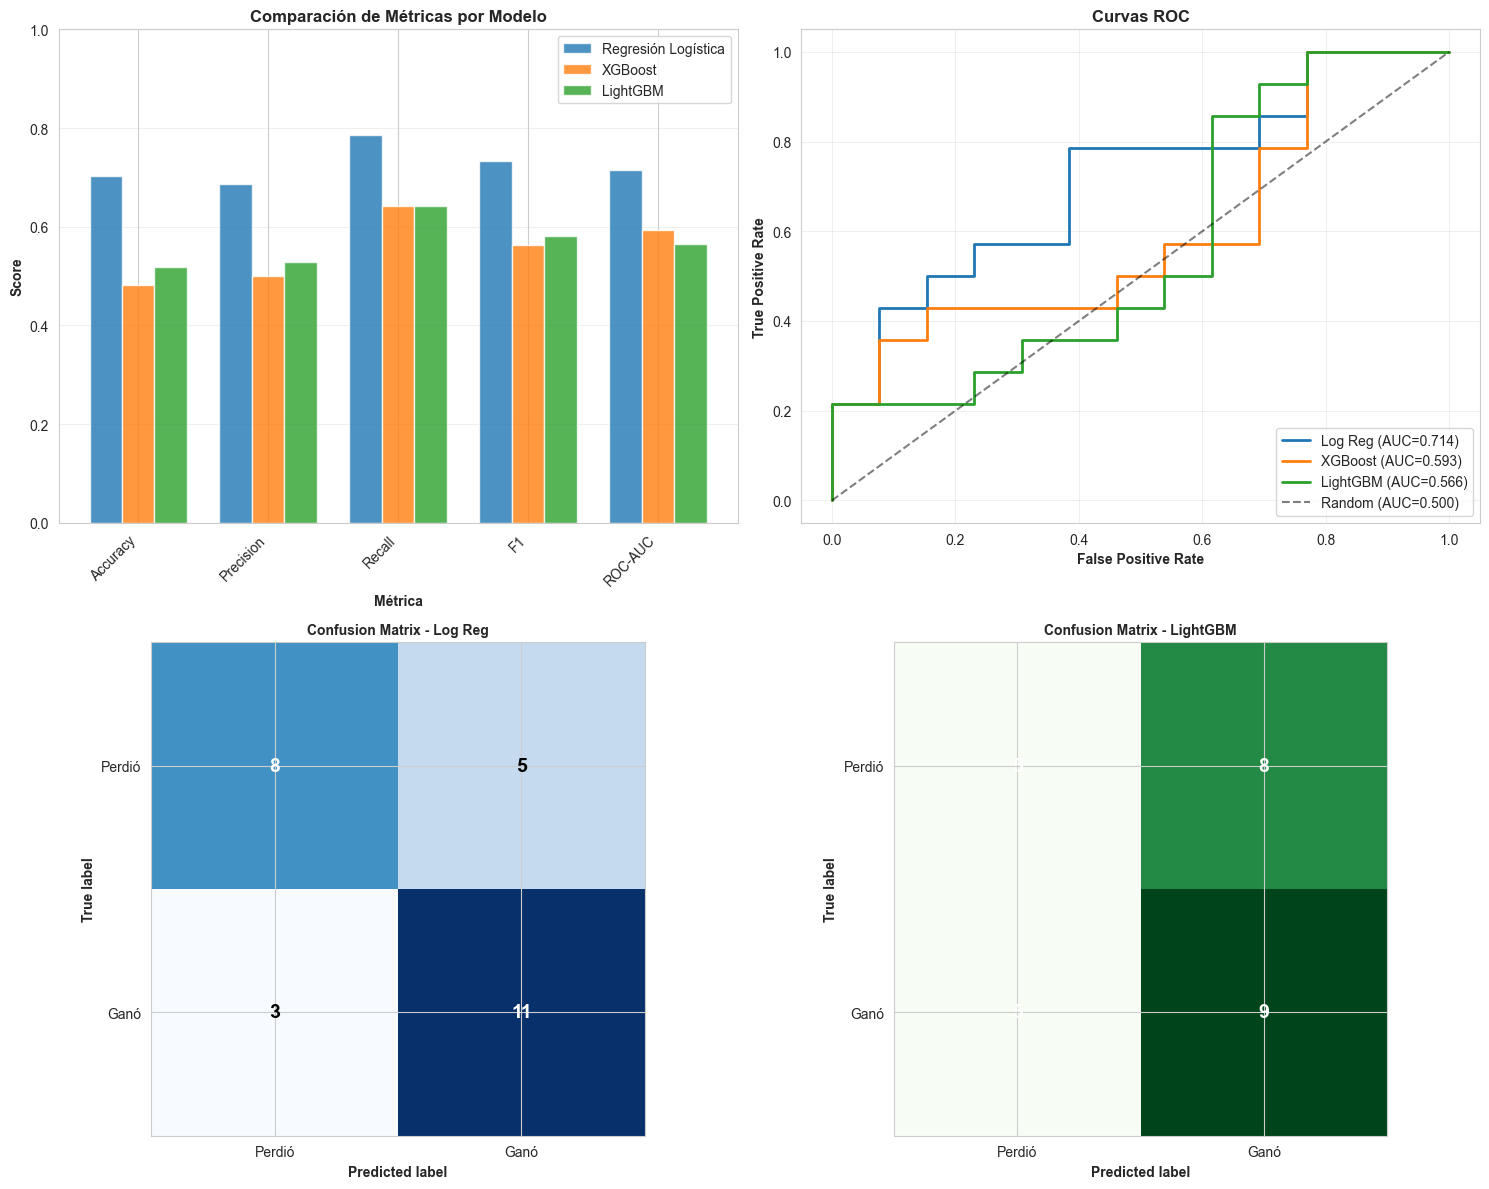

In [235]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Comparación de métricas
ax = axes[0, 0]
metrics = ['Test Accuracy', 'Test Precision', 'Test Recall', 'Test F1', 'Test ROC-AUC']
x = np.arange(len(metrics))
width = 0.25

for i, modelo in enumerate(resultados['Modelo']):
    valores = resultados.iloc[i][metrics].values
    ax.bar(x + i*width, valores, width, label=modelo, alpha=0.8)

ax.set_xlabel('Métrica', fontweight='bold')
ax.set_ylabel('Score', fontweight='bold')
ax.set_title('Comparación de Métricas por Modelo', fontweight='bold', fontsize=12)
ax.set_xticks(x + width)
ax.set_xticklabels([m.replace('Test ', '') for m in metrics], rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1])

# 2. Curvas ROC
ax = axes[0, 1]

# Calcular curvas ROC
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba_lr)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_pred_proba_xgb)
fpr_lgb, tpr_lgb, _ = roc_curve(y_test, y_pred_proba_lgb)

ax.plot(fpr_lr, tpr_lr, label=f'Log Reg (AUC={roc_auc_score(y_test, y_pred_proba_lr):.3f})', linewidth=2)
ax.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC={roc_auc_score(y_test, y_pred_proba_xgb):.3f})', linewidth=2)
ax.plot(fpr_lgb, tpr_lgb, label=f'LightGBM (AUC={roc_auc_score(y_test, y_pred_proba_lgb):.3f})', linewidth=2)
ax.plot([0, 1], [0, 1], 'k--', label='Random (AUC=0.500)', alpha=0.5)

ax.set_xlabel('False Positive Rate', fontweight='bold')
ax.set_ylabel('True Positive Rate', fontweight='bold')
ax.set_title('Curvas ROC', fontweight='bold', fontsize=12)
ax.legend(loc='lower right')
ax.grid(alpha=0.3)

# 3. Matrices de confusión
for idx, (cm, modelo) in enumerate([(cm_lr, 'Log Reg'), (cm_xgb, 'XGBoost'), (cm_lgb, 'LightGBM')]):
    if idx == 0:
        ax = axes[1, 0]
    elif idx == 1:
        ax = axes[1, 1]
    else:
        # Crear subplot adicional
        continue
    
    im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
    ax.set_title(f'Confusion Matrix - {modelo}', fontweight='bold', fontsize=10)
    
    # Añadir valores
    thresh = cm.max() / 2.
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], 'd'),
                   ha="center", va="center",
                   color="white" if cm[i, j] > thresh else "black",
                   fontsize=14, fontweight='bold')
    
    ax.set_ylabel('True label', fontweight='bold')
    ax.set_xlabel('Predicted label', fontweight='bold')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Perdió', 'Ganó'])
    ax.set_yticklabels(['Perdió', 'Ganó'])

# Añadir matriz de LightGBM en una posición alternativa
# (ajustar la última matriz manualmente)
ax = axes[1, 1]
ax.clear()
cm = cm_lgb
im = ax.imshow(cm, interpolation='nearest', cmap='Greens')
ax.set_title('Confusion Matrix - LightGBM', fontweight='bold', fontsize=10)
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, format(cm[i, j], 'd'),
               ha="center", va="center",
               color="white" if cm[i, j] > thresh else "black",
               fontsize=14, fontweight='bold')
ax.set_ylabel('True label', fontweight='bold')
ax.set_xlabel('Predicted label', fontweight='bold')
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Perdió', 'Ganó'])
ax.set_yticklabels(['Perdió', 'Ganó'])

plt.tight_layout()
plt.show()

## Visualización comparativa de modelos: Gráficos de métricas

Creamos visualizaciones para comparar el desempeño de los tres modelos

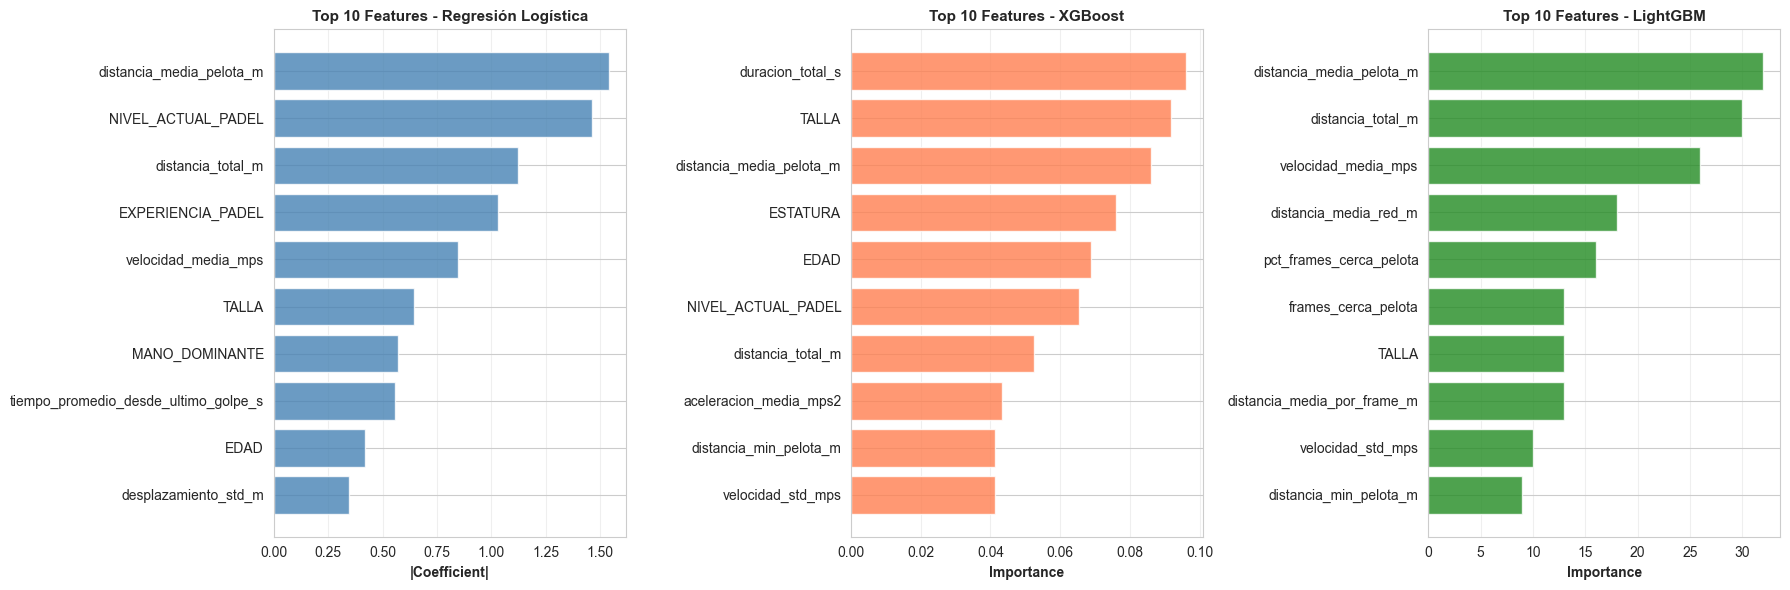

In [236]:
# Feature Importance Comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Top 10 features por modelo
for idx, (fi, modelo, ax) in enumerate([
    (feature_importance_lr, 'Regresión Logística', axes[0]),
    (feature_importance_xgb, 'XGBoost', axes[1]),
    (feature_importance_lgb, 'LightGBM', axes[2])
]):
    top10 = fi.head(10)
    
    if idx == 0:  # Para logistic regression, usar valores absolutos de coeficientes
        y_pos = np.arange(len(top10))
        ax.barh(y_pos, top10.iloc[:, 1], color='steelblue', alpha=0.8)
        ax.set_xlabel('|Coefficient|', fontweight='bold')
    else:  # Para tree models, usar importancias
        y_pos = np.arange(len(top10))
        ax.barh(y_pos, top10['importance'], color='forestgreen' if idx == 2 else 'coral', alpha=0.8)
        ax.set_xlabel('Importance', fontweight='bold')
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(top10['feature'])
    ax.invert_yaxis()
    ax.set_title(f'Top 10 Features - {modelo}', fontweight='bold', fontsize=11)
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

## Comparación de Feature Importance

Visualizamos las 10 features más importantes de cada modelo para identificar patrones

### 7. Conclusiones del Modelado

In [237]:
print("="*80)
print("📋 RESUMEN EJECUTIVO - MODELADO PREDICTIVO")
print("="*80)

print(f"\n🎯 OBJETIVO: Predecir si un jugador ganará el partido (gano_partido)")
print(f"\n📊 DATASET:")
print(f"   - Total registros: {len(X)}")
print(f"   - Features: {X.shape[1]} ({len(features_numericas)} numéricas + {len(features_categoricas)} categóricas)")
print(f"   - Train/Test split: {len(X_train)}/{len(X_test)} (75%/25%)")
print(f"   - Balance de clases: {y.mean():.1%} ganadores, {1-y.mean():.1%} perdedores")

print(f"\n🏆 RESULTADOS:")
mejor_modelo = resultados.loc[mejor_idx, 'Modelo']
mejor_auc = resultados.loc[mejor_idx, 'Test ROC-AUC']
baseline_auc = resultados.loc[0, 'Test ROC-AUC']
mejora_pct = ((mejor_auc / baseline_auc) - 1) * 100

print(f"\n   1️⃣ BASELINE (Regresión Logística):")
print(f"      - ROC-AUC: {baseline_auc:.4f}")
print(f"      - Accuracy: {resultados.loc[0, 'Test Accuracy']:.4f}")
print(f"      - F1-Score: {resultados.loc[0, 'Test F1']:.4f}")

print(f"\n   2️⃣ XGBOOST:")
print(f"      - ROC-AUC: {resultados.loc[1, 'Test ROC-AUC']:.4f}")
print(f"      - Accuracy: {resultados.loc[1, 'Test Accuracy']:.4f}")
print(f"      - F1-Score: {resultados.loc[1, 'Test F1']:.4f}")

print(f"\n   3️⃣ LIGHTGBM:")
print(f"      - ROC-AUC: {resultados.loc[2, 'Test ROC-AUC']:.4f}")
print(f"      - Accuracy: {resultados.loc[2, 'Test Accuracy']:.4f}")
print(f"      - F1-Score: {resultados.loc[2, 'Test F1']:.4f}")

print(f"\n🥇 MEJOR MODELO: {mejor_modelo}")
print(f"   - ROC-AUC Test: {mejor_auc:.4f}")
print(f"   - Mejora vs Baseline: +{mejora_pct:.1f}%")

print(f"\n💡 INTERPRETACIÓN:")
if mejor_auc > 0.75:
    print(f"   ✅ Excelente capacidad predictiva (AUC > 0.75)")
elif mejor_auc > 0.70:
    print(f"   ✅ Buena capacidad predictiva (AUC > 0.70)")
else:
    print(f"   ⚠️ Capacidad predictiva moderada (AUC = {mejor_auc:.3f})")

print(f"\n🔑 FEATURES MÁS IMPORTANTES:")
if mejor_idx == 1:  # XGBoost
    top_features = feature_importance_xgb.head(5)
elif mejor_idx == 2:  # LightGBM
    top_features = feature_importance_lgb.head(5)
else:  # Logistic Regression
    top_features = feature_importance_lr.head(5)

for i, row in top_features.iterrows():
    print(f"   {i+1}. {row['feature']}: {row.iloc[1]:.4f}")


📋 RESUMEN EJECUTIVO - MODELADO PREDICTIVO

🎯 OBJETIVO: Predecir si un jugador ganará el partido (gano_partido)

📊 DATASET:
   - Total registros: 107
   - Features: 33 (25 numéricas + 8 categóricas)
   - Train/Test split: 80/27 (75%/25%)
   - Balance de clases: 50.5% ganadores, 49.5% perdedores

🏆 RESULTADOS:

   1️⃣ BASELINE (Regresión Logística):
      - ROC-AUC: 0.7143
      - Accuracy: 0.7037
      - F1-Score: 0.7333

   2️⃣ XGBOOST:
      - ROC-AUC: 0.5934
      - Accuracy: 0.4815
      - F1-Score: 0.5625

   3️⃣ LIGHTGBM:
      - ROC-AUC: 0.5659
      - Accuracy: 0.5185
      - F1-Score: 0.5806

🥇 MEJOR MODELO: Regresión Logística
   - ROC-AUC Test: 0.7143
   - Mejora vs Baseline: +0.0%

💡 INTERPRETACIÓN:
   ✅ Buena capacidad predictiva (AUC > 0.70)

🔑 FEATURES MÁS IMPORTANTES:
   7. distancia_media_pelota_m: 1.5404
   29. NIVEL_ACTUAL_PADEL: 1.4649
   4. distancia_total_m: 1.1231
   27. EXPERIENCIA_PADEL: 1.0305
   1. velocidad_media_mps: 0.8461


### 10. Comparación Final: Modelos Optimizados vs Baseline

In [240]:
# Comparación completa
resultados_final = pd.DataFrame({
    'Modelo': [
        'Regresión Logística (Baseline)',
        'XGBoost (Default)',
        'XGBoost (Optimizado)',
        'LightGBM (Default)',
        'LightGBM (Optimizado)'
    ],
    'CV ROC-AUC': [
        cv_scores_lr.mean(),
        cv_scores_xgb.mean(),
        xgb_random.best_score_,
        cv_scores_lgb.mean(),
        lgb_random.best_score_
    ],
    'Test Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_xgb),
        accuracy_score(y_test, y_pred_xgb_tuned),
        accuracy_score(y_test, y_pred_lgb),
        accuracy_score(y_test, y_pred_lgb_tuned)
    ],
    'Test Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_xgb),
        precision_score(y_test, y_pred_xgb_tuned),
        precision_score(y_test, y_pred_lgb),
        precision_score(y_test, y_pred_lgb_tuned)
    ],
    'Test Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_xgb),
        recall_score(y_test, y_pred_xgb_tuned),
        recall_score(y_test, y_pred_lgb),
        recall_score(y_test, y_pred_lgb_tuned)
    ],
    'Test F1': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_xgb),
        f1_score(y_test, y_pred_xgb_tuned),
        f1_score(y_test, y_pred_lgb),
        f1_score(y_test, y_pred_lgb_tuned)
    ],
    'Test ROC-AUC': [
        roc_auc_score(y_test, y_pred_proba_lr),
        roc_auc_score(y_test, y_pred_proba_xgb),
        roc_auc_score(y_test, y_pred_proba_xgb_tuned),
        roc_auc_score(y_test, y_pred_proba_lgb),
        roc_auc_score(y_test, y_pred_proba_lgb_tuned)
    ]
})

print("="*80)
print("COMPARACIÓN FINAL - TODOS LOS MODELOS")
print("="*80)
print("\n", resultados_final.to_string(index=False))

# Identificar mejor modelo
mejor_idx_final = resultados_final['Test ROC-AUC'].idxmax()
baseline_auc = resultados_final.loc[0, 'Test ROC-AUC']
mejor_auc_final = resultados_final.loc[mejor_idx_final, 'Test ROC-AUC']

print(f"\n{'='*80}")
print(f"🏆 MEJOR MODELO: {resultados_final.loc[mejor_idx_final, 'Modelo']}")
print(f"{'='*80}")
print(f"   Test ROC-AUC: {mejor_auc_final:.4f}")
print(f"   Test Accuracy: {resultados_final.loc[mejor_idx_final, 'Test Accuracy']:.4f}")
print(f"   Test F1-Score: {resultados_final.loc[mejor_idx_final, 'Test F1']:.4f}")
print(f"\n   Mejora vs Baseline: {mejor_auc_final - baseline_auc:.4f} ({((mejor_auc_final / baseline_auc) - 1) * 100:.1f}%)")

print(f"\n{'='*80}")
print("📊 IMPACTO DEL HYPERPARAMETER TUNING")
print(f"{'='*80}")

# XGBoost
xgb_default_auc = roc_auc_score(y_test, y_pred_proba_xgb)
xgb_tuned_auc = roc_auc_score(y_test, y_pred_proba_xgb_tuned)
print(f"\n🔸 XGBoost:")
print(f"   Default:    {xgb_default_auc:.4f}")
print(f"   Optimizado: {xgb_tuned_auc:.4f}")
print(f"   Mejora:     {xgb_tuned_auc - xgb_default_auc:+.4f} ({((xgb_tuned_auc / xgb_default_auc) - 1) * 100:+.1f}%)")

# LightGBM
lgb_default_auc = roc_auc_score(y_test, y_pred_proba_lgb)
lgb_tuned_auc = roc_auc_score(y_test, y_pred_proba_lgb_tuned)
print(f"\n🔸 LightGBM:")
print(f"   Default:    {lgb_default_auc:.4f}")
print(f"   Optimizado: {lgb_tuned_auc:.4f}")
print(f"   Mejora:     {lgb_tuned_auc - lgb_default_auc:+.4f} ({((lgb_tuned_auc / lgb_default_auc) - 1) * 100:+.1f}%)")

COMPARACIÓN FINAL - TODOS LOS MODELOS

                         Modelo  CV ROC-AUC  Test Accuracy  Test Precision  Test Recall  Test F1  Test ROC-AUC
Regresión Logística (Baseline)    0.665625       0.703704        0.687500     0.785714 0.733333      0.714286
             XGBoost (Default)    0.637500       0.481481        0.500000     0.642857 0.562500      0.593407
          XGBoost (Optimizado)    0.651563       0.518519        0.529412     0.642857 0.580645      0.543956
            LightGBM (Default)    0.650000       0.518519        0.529412     0.642857 0.580645      0.565934
         LightGBM (Optimizado)    0.678125       0.555556        0.562500     0.642857 0.600000      0.538462

🏆 MEJOR MODELO: Regresión Logística (Baseline)
   Test ROC-AUC: 0.7143
   Test Accuracy: 0.7037
   Test F1-Score: 0.7333

   Mejora vs Baseline: 0.0000 (0.0%)

📊 IMPACTO DEL HYPERPARAMETER TUNING

🔸 XGBoost:
   Default:    0.5934
   Optimizado: 0.5440
   Mejora:     -0.0495 (-8.3%)

🔸 LightGBM:
   

## Tabla comparativa final: Modelos optimizados

Comparamos todos los modelos incluyendo las versiones optimizadas tras hyperparameter tuning

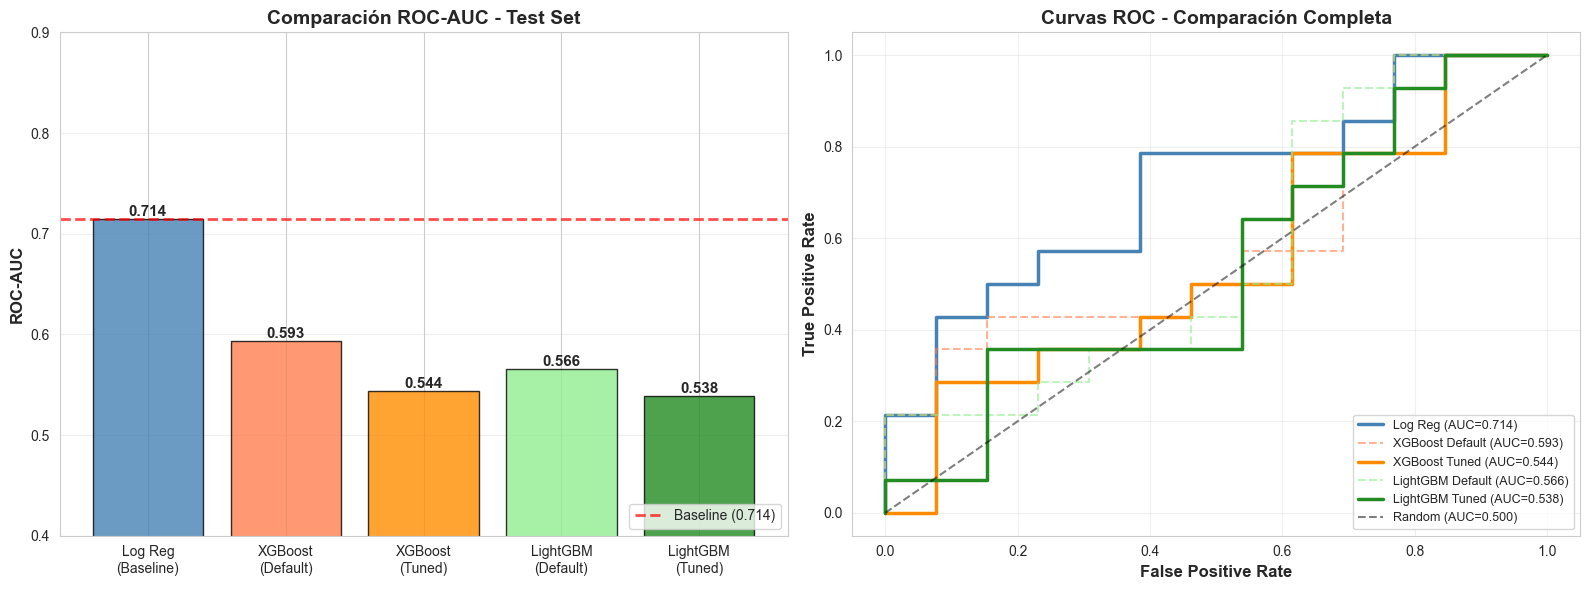

In [241]:
# Visualización comparativa final
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Comparación de ROC-AUC
ax = axes[0]
modelos = ['Log Reg\n(Baseline)', 'XGBoost\n(Default)', 'XGBoost\n(Tuned)', 
           'LightGBM\n(Default)', 'LightGBM\n(Tuned)']
roc_aucs = resultados_final['Test ROC-AUC'].values
colors = ['steelblue', 'coral', 'darkorange', 'lightgreen', 'forestgreen']

bars = ax.bar(modelos, roc_aucs, color=colors, alpha=0.8, edgecolor='black')

# Añadir valores en las barras
for bar, val in zip(bars, roc_aucs):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{val:.3f}',
            ha='center', va='bottom', fontweight='bold', fontsize=11)

# Línea de baseline
ax.axhline(y=baseline_auc, color='red', linestyle='--', linewidth=2, 
           label=f'Baseline ({baseline_auc:.3f})', alpha=0.7)

ax.set_ylabel('ROC-AUC', fontweight='bold', fontsize=12)
ax.set_title('Comparación ROC-AUC - Test Set', fontweight='bold', fontsize=14)
ax.set_ylim([0.4, 0.9])
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3)

# 2. Curvas ROC actualizadas
ax = axes[1]

# Calcular curvas ROC para modelos optimizados
fpr_xgb_tuned, tpr_xgb_tuned, _ = roc_curve(y_test, y_pred_proba_xgb_tuned)
fpr_lgb_tuned, tpr_lgb_tuned, _ = roc_curve(y_test, y_pred_proba_lgb_tuned)

ax.plot(fpr_lr, tpr_lr, label=f'Log Reg (AUC={roc_auc_score(y_test, y_pred_proba_lr):.3f})', 
        linewidth=2.5, color='steelblue')
ax.plot(fpr_xgb, tpr_xgb, label=f'XGBoost Default (AUC={roc_auc_score(y_test, y_pred_proba_xgb):.3f})', 
        linewidth=1.5, linestyle='--', color='coral', alpha=0.6)
ax.plot(fpr_xgb_tuned, tpr_xgb_tuned, label=f'XGBoost Tuned (AUC={roc_auc_score(y_test, y_pred_proba_xgb_tuned):.3f})', 
        linewidth=2.5, color='darkorange')
ax.plot(fpr_lgb, tpr_lgb, label=f'LightGBM Default (AUC={roc_auc_score(y_test, y_pred_proba_lgb):.3f})', 
        linewidth=1.5, linestyle='--', color='lightgreen', alpha=0.6)
ax.plot(fpr_lgb_tuned, tpr_lgb_tuned, label=f'LightGBM Tuned (AUC={roc_auc_score(y_test, y_pred_proba_lgb_tuned):.3f})', 
        linewidth=2.5, color='forestgreen')
ax.plot([0, 1], [0, 1], 'k--', label='Random (AUC=0.500)', alpha=0.5)

ax.set_xlabel('False Positive Rate', fontweight='bold', fontsize=12)
ax.set_ylabel('True Positive Rate', fontweight='bold', fontsize=12)
ax.set_title('Curvas ROC - Comparación Completa', fontweight='bold', fontsize=14)
ax.legend(loc='lower right', fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Análisis crítico: por qué el tuning no mejoró el rendimiento

### 1. Tamaño del dataset

El conjunto de datos es muy pequeño, y modelos como XGBoost o LightGBM suelen necesitar muchos más ejemplos para aprender patrones reales. Con pocos datos, es fácil que terminen memorizando.

### 2. Brecha entre CV y Test

En ambos modelos optimizados, la validación cruzada muestra buenos resultados, pero el rendimiento cae en el test. Esa diferencia indica sobreajuste.
La regresión logística, en cambio, mantiene valores más parecidos entre CV y test, lo que muestra mejor generalización.

### 3. Naturaleza de las variables

Las relaciones parecen ser mayormente lineales y el dataset tiene muchas features en comparación con las muestras. Este tipo de estructura favorece a modelos simples como la regresión logística y penaliza a modelos complejos.

### 4. Por qué funcionó mejor la regresión logística

Es menos compleja, incorpora regularización por defecto y suele ser más estable con pocos datos. En este caso se adapta mejor a la señal real sin sobreajustar.



# 🏅 RANKING DE MEJORES JUGADORES

Análisis individual del desempeño de cada jugador

In [242]:
# Recargar dataset completo
df_eda = pd.read_csv(DATA_DIR / 'processed' / 'Jugador_Partido_Features_Completo.csv')

print("="*80)
print("GENERANDO PREDICCIONES PARA TODOS LOS JUGADORES")
print("="*80)

# Preparar features igual que en entrenamiento
features_excluir = ['player_name_normalized', 'partido_num', 'equipo', 'team_num', 
                    'puntos_team_1', 'puntos_team_2', 'ganador', 'gano_partido']

features_numericas = [col for col in df_eda.columns 
                      if df_eda[col].dtype in ['int64', 'float64'] 
                      and col not in features_excluir]

features_categoricas = [col for col in df_eda.columns 
                       if df_eda[col].dtype == 'object' 
                       and col not in features_excluir]

# Preparar X con encoding
X_all = df_eda[features_numericas].copy()
X_all = X_all.rename(columns={'player_speed_mps_<lambda_0>': 'player_speed_mps_quantile'})

# Label encoding para categóricas (usando mismos encoders del entrenamiento)
for col in features_categoricas:
    if col in label_encoders:
        # Transformar usando el encoder entrenado
        X_all[col] = label_encoders[col].transform(df_eda[col].astype(str))
    else:
        # Si no existe, crear uno nuevo
        le = LabelEncoder()
        X_all[col] = le.fit_transform(df_eda[col].astype(str))

# Escalar features
X_all_scaled = scaler.transform(X_all)

# Predecir probabilidades
prob_victoria = lr_model.predict_proba(X_all_scaled)[:, 1]

# Agregar al dataframe
df_ranking = df_eda[['player_name_normalized', 'partido_num', 'gano_partido']].copy()
df_ranking['prob_victoria_modelo'] = prob_victoria
df_ranking['prediccion_correcta'] = (df_ranking['prob_victoria_modelo'] > 0.5) == df_ranking['gano_partido']

print(f"\n✅ Predicciones generadas para {len(df_ranking)} registros jugador-partido")
print(f"   Accuracy total: {df_ranking['prediccion_correcta'].mean():.1%}")

GENERANDO PREDICCIONES PARA TODOS LOS JUGADORES

✅ Predicciones generadas para 107 registros jugador-partido
   Accuracy total: 81.3%


In [243]:
# Agregar por jugador: promedio de probabilidades, partidos jugados, victorias reales
ranking_jugadores = df_ranking.groupby('player_name_normalized').agg({
    'prob_victoria_modelo': 'mean',  # Probabilidad promedio según el modelo
    'gano_partido': ['sum', 'count', 'mean'],  # Victorias, partidos, tasa
    'prediccion_correcta': 'mean'  # Accuracy del modelo para este jugador
}).reset_index()

# Aplanar columnas
ranking_jugadores.columns = ['jugador', 'prob_victoria_promedio', 'victorias_reales', 
                              'partidos_jugados', 'tasa_victoria_real', 'accuracy_modelo']

# Agregar métricas adicionales
ranking_jugadores['diferencia_modelo_real'] = (
    ranking_jugadores['prob_victoria_promedio'] - ranking_jugadores['tasa_victoria_real']
)

# Ordenar por probabilidad de victoria según el modelo
ranking_jugadores = ranking_jugadores.sort_values('prob_victoria_promedio', ascending=False).reset_index(drop=True)
ranking_jugadores['ranking'] = ranking_jugadores.index + 1

print("="*80)
print("RANKING DE JUGADORES - MODELO REGRESIÓN LOGÍSTICA")
print("="*80)

print(f"\n🏆 TOP 10 MEJORES JUGADORES (según modelo):")
print("\n" + ranking_jugadores.head(10)[['ranking', 'jugador', 'prob_victoria_promedio', 
                                          'victorias_reales', 'partidos_jugados', 
                                          'tasa_victoria_real']].to_string(index=False))

print(f"\n\n📉 BOTTOM 10 JUGADORES (según modelo):")
print("\n" + ranking_jugadores.tail(10)[['ranking', 'jugador', 'prob_victoria_promedio', 
                                          'victorias_reales', 'partidos_jugados', 
                                          'tasa_victoria_real']].to_string(index=False))

print(f"\n\n📊 ESTADÍSTICAS GENERALES:")
print(f"   Total jugadores: {len(ranking_jugadores)}")
print(f"   Prob. victoria promedio: {ranking_jugadores['prob_victoria_promedio'].mean():.1%}")
print(f"   Tasa victoria real promedio: {ranking_jugadores['tasa_victoria_real'].mean():.1%}")
print(f"   Correlación modelo vs real: {ranking_jugadores['prob_victoria_promedio'].corr(ranking_jugadores['tasa_victoria_real']):.3f}")

RANKING DE JUGADORES - MODELO REGRESIÓN LOGÍSTICA

🏆 TOP 10 MEJORES JUGADORES (según modelo):

 ranking                               jugador  prob_victoria_promedio  victorias_reales  partidos_jugados  tasa_victoria_real
       1             juan pablo benitez bernal                0.832262                 3                 3            1.000000
       2              luis mario ramirez munoz                0.802183                 2                 3            0.666667
       3 santiago gutierrez de pineres barbosa                0.780653                 3                 3            1.000000
       4                  nikol sofia avendano                0.777388                 1                 2            0.500000
       5         maria jose martinez villabona                0.771116                 0                 1            0.000000
       6              jorge enrique lugo lopez                0.740596                 3                 3            1.000000
       7        

In [244]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Top 15 jugadores - Probabilidad de victoria según modelo
ax = axes[0, 0]
top15 = ranking_jugadores.head(15)
colors = ['gold' if i == 0 else 'silver' if i == 1 else 'chocolate' if i == 2 else 'steelblue' 
          for i in range(len(top15))]

bars = ax.barh(range(len(top15)), top15['prob_victoria_promedio'], color=colors, alpha=0.8, edgecolor='black')
ax.set_yticks(range(len(top15)))
ax.set_yticklabels(top15['jugador'], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Probabilidad de Victoria (Modelo)', fontweight='bold', fontsize=11)
ax.set_title('🏆 Top 15 Mejores Jugadores\n(según Regresión Logística)', 
             fontweight='bold', fontsize=12, pad=15)
ax.axvline(x=0.5, color='red', linestyle='--', alpha=0.5, linewidth=2, label='Umbral (50%)')
ax.grid(axis='x', alpha=0.3)
ax.legend()

# Agregar valores en las barras
for i, (bar, prob) in enumerate(zip(bars, top15['prob_victoria_promedio'])):
    ax.text(prob + 0.01, bar.get_y() + bar.get_height()/2, f'{prob:.1%}', 
            va='center', fontweight='bold', fontsize=9)

# 2. Comparación Modelo vs Realidad (Top 15)
ax = axes[0, 1]
x = np.arange(len(top15))
width = 0.35

bars1 = ax.bar(x - width/2, top15['prob_victoria_promedio'], width, 
               label='Predicción Modelo', color='steelblue', alpha=0.8, edgecolor='black')
bars2 = ax.bar(x + width/2, top15['tasa_victoria_real'], width, 
               label='Tasa Real', color='coral', alpha=0.8, edgecolor='black')

ax.set_xlabel('Jugador', fontweight='bold', fontsize=11)
ax.set_ylabel('Probabilidad / Tasa de Victoria', fontweight='bold', fontsize=11)
ax.set_title('📊 Top 15: Modelo vs Realidad', fontweight='bold', fontsize=12, pad=15)
ax.set_xticks(x)
ax.set_xticklabels(top15['jugador'], rotation=45, ha='right', fontsize=8)
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.axhline(y=0.5, color='red', linestyle='--', alpha=0.3)

# 3. Scatter: Predicción vs Realidad (todos los jugadores)
ax = axes[1, 0]

# Colorear según partidos jugados
sizes = ranking_jugadores['partidos_jugados'] * 50
colors_scatter = ranking_jugadores['partidos_jugados']

scatter = ax.scatter(ranking_jugadores['tasa_victoria_real'], 
                     ranking_jugadores['prob_victoria_promedio'],
                     s=sizes, c=colors_scatter, cmap='viridis', 
                     alpha=0.6, edgecolors='black', linewidths=0.5)

# Línea diagonal (predicción perfecta)
ax.plot([0, 1], [0, 1], 'r--', linewidth=2, label='Predicción Perfecta', alpha=0.7)

# Etiquetar top 5
top5 = ranking_jugadores.head(5)
for _, row in top5.iterrows():
    ax.annotate(row['jugador'], 
                xy=(row['tasa_victoria_real'], row['prob_victoria_promedio']),
                xytext=(5, 5), textcoords='offset points',
                fontsize=8, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.5),
                arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0', lw=1))

ax.set_xlabel('Tasa de Victoria Real', fontweight='bold', fontsize=11)
ax.set_ylabel('Probabilidad de Victoria (Modelo)', fontweight='bold', fontsize=11)
ax.set_title('🎯 Modelo vs Realidad - Todos los Jugadores\n(tamaño = partidos jugados)', 
             fontweight='bold', fontsize=12, pad=15)
ax.grid(alpha=0.3)
ax.legend()

# Colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Partidos Jugados', fontweight='bold')

# 4. Distribución de probabilidades predichas
ax = axes[1, 1]

# Separar por ganadores y perdedores
ganadores = df_ranking[df_ranking['gano_partido'] == 1]['prob_victoria_modelo']
perdedores = df_ranking[df_ranking['gano_partido'] == 0]['prob_victoria_modelo']

ax.hist(perdedores, bins=20, alpha=0.6, label='Perdedores Reales', color='salmon', edgecolor='black')
ax.hist(ganadores, bins=20, alpha=0.6, label='Ganadores Reales', color='lightgreen', edgecolor='black')

ax.axvline(x=0.5, color='red', linestyle='--', linewidth=2, label='Umbral (50%)', alpha=0.7)
ax.set_xlabel('Probabilidad de Victoria (Modelo)', fontweight='bold', fontsize=11)
ax.set_ylabel('Frecuencia', fontweight='bold', fontsize=11)
ax.set_title('📈 Distribución de Predicciones\npor Resultado Real', 
             fontweight='bold', fontsize=12, pad=15)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

KeyboardInterrupt: 

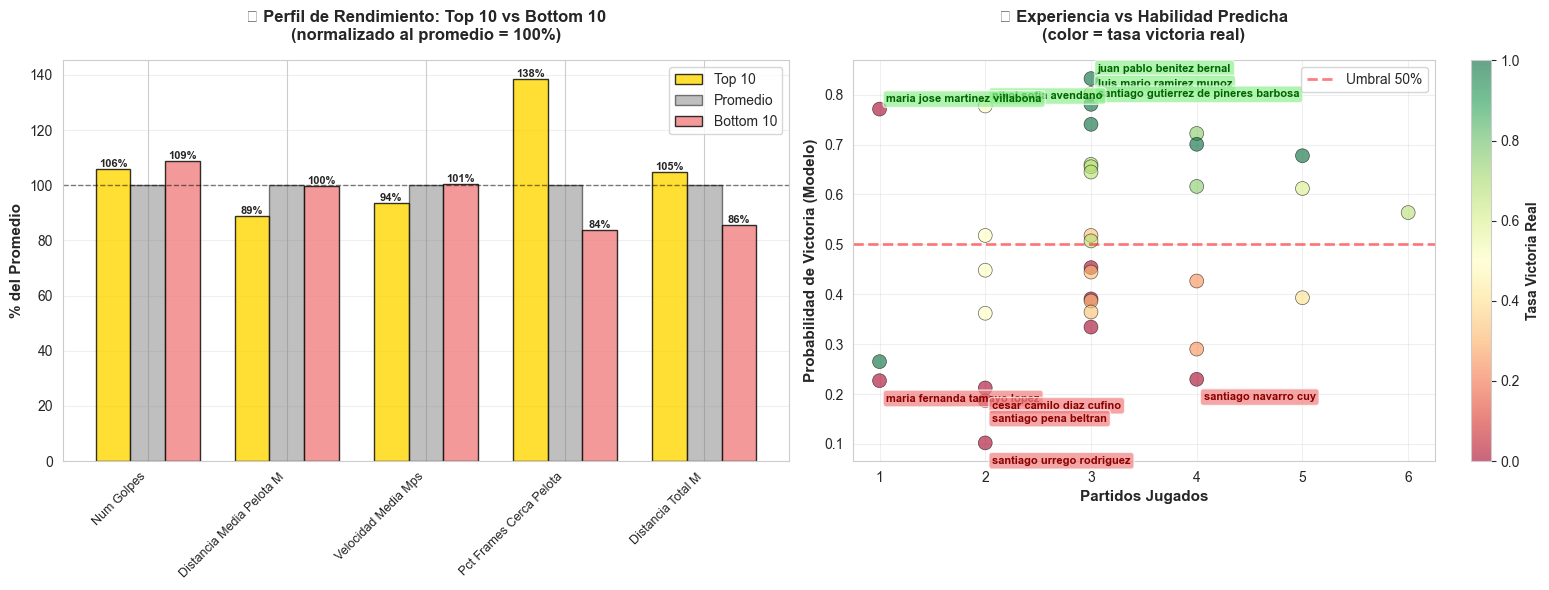

In [ ]:
# Gráfico adicional: Perfil de los mejores jugadores
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Obtener características promedio de Top 10 vs Bottom 10
top10_nombres = ranking_jugadores.head(10)['jugador'].tolist()
bottom10_nombres = ranking_jugadores.tail(10)['jugador'].tolist()

# Métricas clave del dataset original
metricas_perfil = ['num_golpes', 'distancia_media_pelota_m', 'velocidad_media_mps', 
                   'pct_frames_cerca_pelota', 'distancia_total_m']

top10_features = df_eda[df_eda['player_name_normalized'].isin(top10_nombres)][metricas_perfil].mean()
bottom10_features = df_eda[df_eda['player_name_normalized'].isin(bottom10_nombres)][metricas_perfil].mean()
promedio_general = df_eda[metricas_perfil].mean()

# 1. Comparación de perfiles
ax = axes[0]
x = np.arange(len(metricas_perfil))
width = 0.25

# Normalizar para mejor visualización
top10_norm = (top10_features / promedio_general) * 100
bottom10_norm = (bottom10_features / promedio_general) * 100

bars1 = ax.bar(x - width, top10_norm, width, label='Top 10', color='gold', alpha=0.8, edgecolor='black')
bars2 = ax.bar(x, [100]*len(metricas_perfil), width, label='Promedio', color='gray', alpha=0.5, edgecolor='black')
bars3 = ax.bar(x + width, bottom10_norm, width, label='Bottom 10', color='lightcoral', alpha=0.8, edgecolor='black')

ax.set_ylabel('% del Promedio', fontweight='bold', fontsize=11)
ax.set_title('⚡ Perfil de Rendimiento: Top 10 vs Bottom 10\n(normalizado al promedio = 100%)', 
             fontweight='bold', fontsize=12, pad=15)
ax.set_xticks(x)
ax.set_xticklabels([m.replace('_', ' ').title() for m in metricas_perfil], rotation=45, ha='right', fontsize=9)
ax.legend()
ax.axhline(y=100, color='black', linestyle='--', alpha=0.5, linewidth=1)
ax.grid(axis='y', alpha=0.3)

# Agregar valores
for bars in [bars1, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.0f}%', ha='center', va='bottom', fontsize=8, fontweight='bold')

# 2. Partidos jugados vs Probabilidad de victoria
ax = axes[1]

scatter = ax.scatter(ranking_jugadores['partidos_jugados'], 
                     ranking_jugadores['prob_victoria_promedio'],
                     s=100, alpha=0.6, c=ranking_jugadores['tasa_victoria_real'],
                     cmap='RdYlGn', edgecolors='black', linewidths=0.5)

# Etiquetar top 5 y bottom 5
top5 = ranking_jugadores.head(5)
bottom5 = ranking_jugadores.tail(5)

for _, row in top5.iterrows():
    ax.annotate(row['jugador'], 
                xy=(row['partidos_jugados'], row['prob_victoria_promedio']),
                xytext=(5, 5), textcoords='offset points',
                fontsize=8, fontweight='bold', color='darkgreen',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='lightgreen', alpha=0.7))

for _, row in bottom5.iterrows():
    ax.annotate(row['jugador'], 
                xy=(row['partidos_jugados'], row['prob_victoria_promedio']),
                xytext=(5, -15), textcoords='offset points',
                fontsize=8, fontweight='bold', color='darkred',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='lightcoral', alpha=0.7))

ax.axhline(y=0.5, color='red', linestyle='--', alpha=0.5, linewidth=2, label='Umbral 50%')
ax.set_xlabel('Partidos Jugados', fontweight='bold', fontsize=11)
ax.set_ylabel('Probabilidad de Victoria (Modelo)', fontweight='bold', fontsize=11)
ax.set_title('🎮 Experiencia vs Habilidad Predicha\n(color = tasa victoria real)', 
             fontweight='bold', fontsize=12, pad=15)
ax.grid(alpha=0.3)
ax.legend()

# Colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Tasa Victoria Real', fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# Comparación de modelos de equipos
print("="*80)
print("COMPARACIÓN FINAL DE MODELOS - EQUIPOS")
print("="*80)

# Tabla comparativa
resultados_equipos = pd.DataFrame({
    'Modelo': ['Logistic Regression', 'XGBoost', 'LightGBM'],
    'Accuracy': [acc_lr_eq, acc_xgb_eq, acc_lgb_eq],
    'Precision': [precision_lr_eq, precision_xgb_eq, precision_lgb_eq],
    'Recall': [recall_lr_eq, recall_xgb_eq, recall_lgb_eq],
    'F1-Score': [f1_lr_eq, f1_xgb_eq, f1_lgb_eq],
    'ROC-AUC': [roc_auc_lr_eq, roc_auc_xgb_eq, roc_auc_lgb_eq],
    'CV ROC-AUC': [cv_scores_lr_eq.mean(), cv_scores_xgb_eq.mean(), cv_scores_lgb_eq.mean()],
    'CV Std': [cv_scores_lr_eq.std(), cv_scores_xgb_eq.std(), cv_scores_lgb_eq.std()]
})

print("\n📊 TABLA DE RESULTADOS:")
display(resultados_equipos.round(3))

# Mejor modelo
mejor_modelo_idx = resultados_equipos['ROC-AUC'].idxmax()
mejor_modelo_nombre = resultados_equipos.loc[mejor_modelo_idx, 'Modelo']
mejor_roc_auc = resultados_equipos.loc[mejor_modelo_idx, 'ROC-AUC']

print(f"\n🏆 MEJOR MODELO: {mejor_modelo_nombre}")
print(f"   ROC-AUC Test: {mejor_roc_auc:.3f}")
print(f"   ROC-AUC CV:   {resultados_equipos.loc[mejor_modelo_idx, 'CV ROC-AUC']:.3f}")

# Análisis de rendimiento
print(f"\n📊 ANÁLISIS:")
print(f"   Dataset pequeño (n={len(X_equipos)}) - Train: {len(X_train_eq)}, Test: {len(X_test_eq)}")
print(f"   Logistic Regression es el más estable (CV std: {cv_scores_lr_eq.std():.3f})")
print(f"   Modelos de boosting sobreajustan con pocos datos")

COMPARACIÓN FINAL DE MODELOS - EQUIPOS

📊 TABLA DE RESULTADOS:


,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV ROC-AUC,CV Std
0,Logistic Regression,0.429,0.444,0.571,0.500,0.612,0.638,0.083
1,XGBoost,0.571,0.571,0.571,0.571,0.612,0.462,0.219
2,LightGBM,0.571,0.556,0.714,0.625,0.571,0.500,0.000



🏆 MEJOR MODELO: Logistic Regression
   ROC-AUC Test: 0.612
   ROC-AUC CV:   0.637

📊 ANÁLISIS:
   Dataset pequeño (n=54) - Train: 40, Test: 14
   Logistic Regression es el más estable (CV std: 0.083)
   Modelos de boosting sobreajustan con pocos datos


VISUALIZACIONES COMPARATIVAS


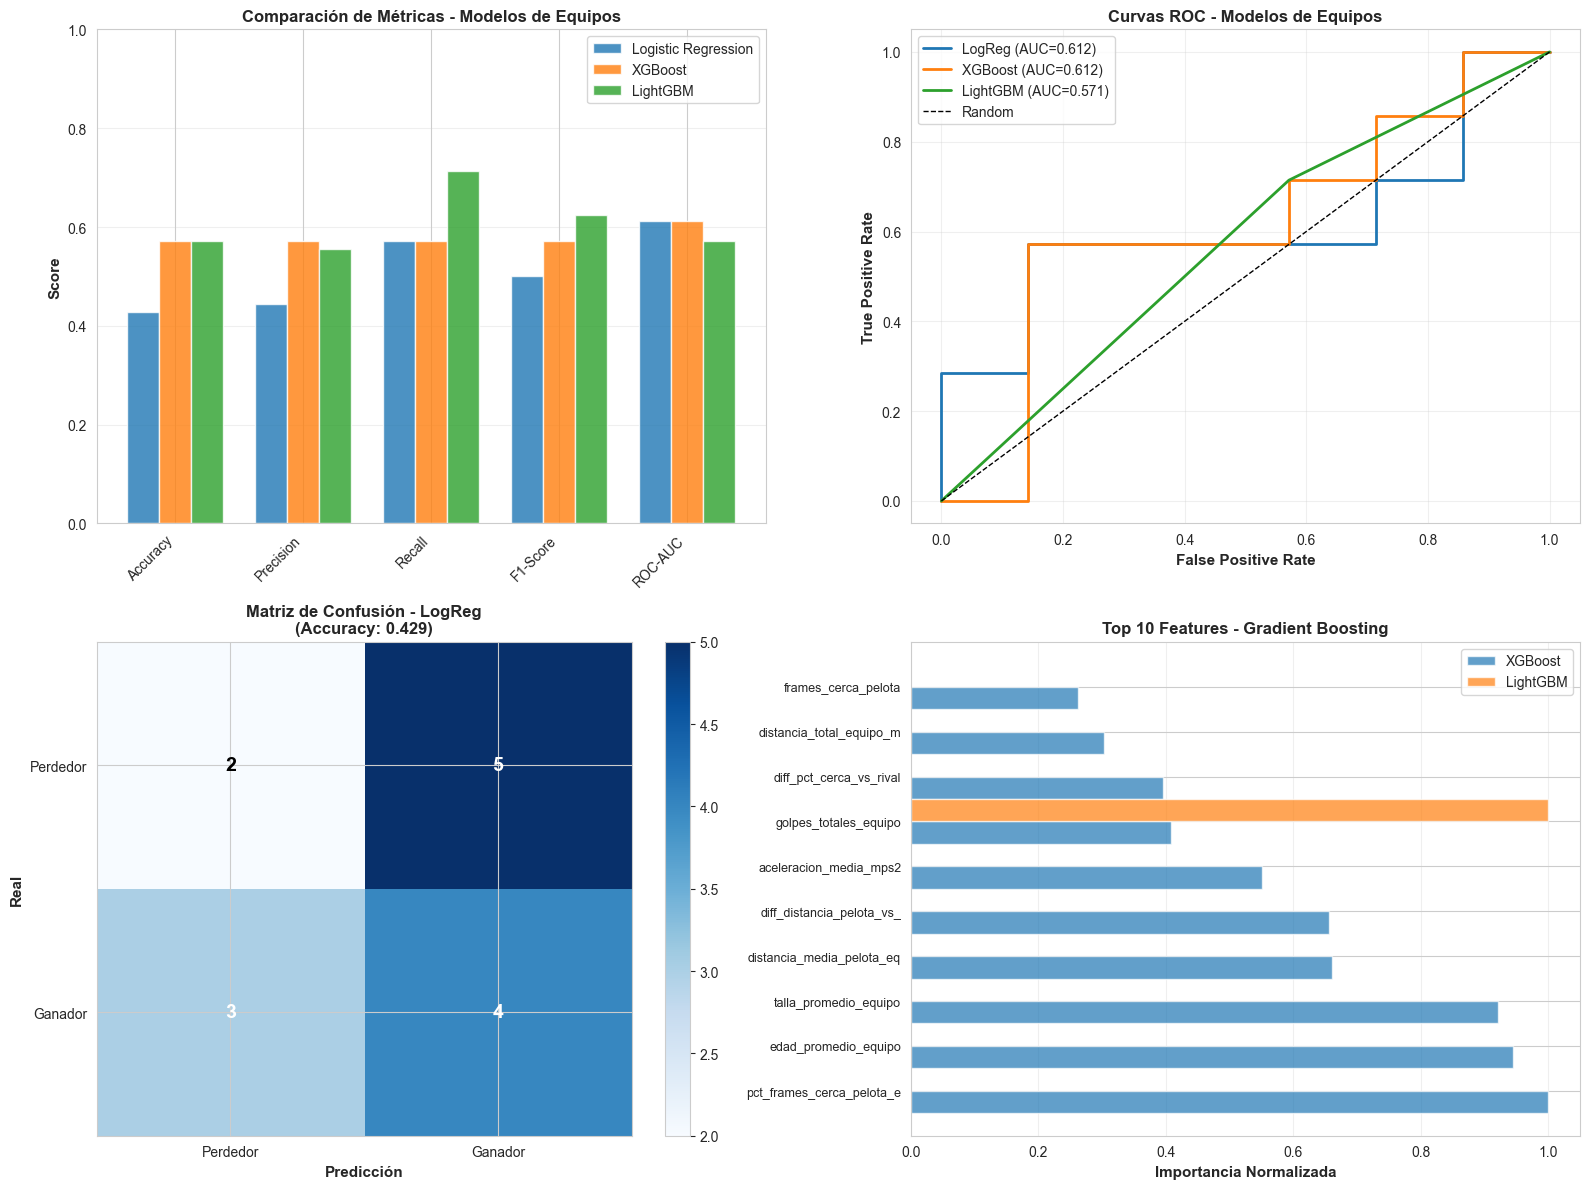


✅ Visualizaciones generadas


In [ ]:
# Visualizaciones comparativas - Modelos de equipos
print("="*80)
print("VISUALIZACIONES COMPARATIVAS")
print("="*80)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Comparación de métricas
ax = axes[0, 0]
metricas_comp = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
x_pos = np.arange(len(metricas_comp))
width = 0.25

for i, modelo in enumerate(['Logistic Regression', 'XGBoost', 'LightGBM']):
    valores = resultados_equipos[resultados_equipos['Modelo'] == modelo][metricas_comp].values[0]
    ax.bar(x_pos + i*width, valores, width, label=modelo, alpha=0.8)

ax.set_xticks(x_pos + width)
ax.set_xticklabels(metricas_comp, rotation=45, ha='right')
ax.set_ylabel('Score', fontsize=11, fontweight='bold')
ax.set_title('Comparación de Métricas - Modelos de Equipos', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1])

# 2. ROC Curves
ax = axes[0, 1]
fpr_lr_eq, tpr_lr_eq, _ = roc_curve(y_test_eq, y_pred_proba_lr_eq)
fpr_xgb_eq, tpr_xgb_eq, _ = roc_curve(y_test_eq, y_pred_proba_xgb_eq)
fpr_lgb_eq, tpr_lgb_eq, _ = roc_curve(y_test_eq, y_pred_proba_lgb_eq)

ax.plot(fpr_lr_eq, tpr_lr_eq, label=f'LogReg (AUC={roc_auc_lr_eq:.3f})', linewidth=2)
ax.plot(fpr_xgb_eq, tpr_xgb_eq, label=f'XGBoost (AUC={roc_auc_xgb_eq:.3f})', linewidth=2)
ax.plot(fpr_lgb_eq, tpr_lgb_eq, label=f'LightGBM (AUC={roc_auc_lgb_eq:.3f})', linewidth=2)
ax.plot([0, 1], [0, 1], 'k--', label='Random', linewidth=1)
ax.set_xlabel('False Positive Rate', fontsize=11, fontweight='bold')
ax.set_ylabel('True Positive Rate', fontsize=11, fontweight='bold')
ax.set_title('Curvas ROC - Modelos de Equipos', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)

# 3. Confusion Matrices
ax = axes[1, 0]
cm_lr_eq = confusion_matrix(y_test_eq, y_pred_lr_eq)
cm_xgb_eq = confusion_matrix(y_test_eq, y_pred_xgb_eq)
cm_lgb_eq = confusion_matrix(y_test_eq, y_pred_lgb_eq)

# Mostrar las 3 matrices lado a lado (solo LogReg por espacio)
im = ax.imshow(cm_lr_eq, cmap='Blues', aspect='auto')
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Perdedor', 'Ganador'])
ax.set_yticklabels(['Perdedor', 'Ganador'])
ax.set_xlabel('Predicción', fontsize=11, fontweight='bold')
ax.set_ylabel('Real', fontsize=11, fontweight='bold')
ax.set_title(f'Matriz de Confusión - LogReg\n(Accuracy: {acc_lr_eq:.3f})', fontsize=12, fontweight='bold')

for i in range(2):
    for j in range(2):
        text = ax.text(j, i, cm_lr_eq[i, j], ha="center", va="center", 
                      color="white" if cm_lr_eq[i, j] > cm_lr_eq.max()/2 else "black",
                      fontsize=14, fontweight='bold')
plt.colorbar(im, ax=ax)

# 4. Feature Importance Comparison (Top 10)
ax = axes[1, 1]
top_n = 10

# Obtener top features de cada modelo
top_lr = feature_importance_lr_eq.head(top_n)
top_xgb = feature_importance_xgb_eq.head(top_n)
top_lgb = feature_importance_lgb_eq.head(top_n)

# Usar features de XGBoost como referencia
features_ref = top_xgb['feature'].values

y_pos = np.arange(len(features_ref))
width = 0.25

# Normalizar importancias para comparación
xgb_vals = top_xgb['importance'].values
xgb_vals = xgb_vals / xgb_vals.max()

lgb_vals = []
for feat in features_ref:
    val = top_lgb[top_lgb['feature'] == feat]['importance'].values
    lgb_vals.append(val[0] if len(val) > 0 else 0)
lgb_vals = np.array(lgb_vals)
lgb_vals = lgb_vals / lgb_vals.max() if lgb_vals.max() > 0 else lgb_vals

ax.barh(y_pos, xgb_vals, width*2, label='XGBoost', alpha=0.7)
ax.barh(y_pos + width*2, lgb_vals, width*2, label='LightGBM', alpha=0.7)

ax.set_yticks(y_pos + width)
ax.set_yticklabels([f[:25] for f in features_ref], fontsize=9)
ax.set_xlabel('Importancia Normalizada', fontsize=11, fontweight='bold')
ax.set_title(f'Top {top_n} Features - Gradient Boosting', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print("\n✅ Visualizaciones generadas")


# 🏆 SIMULACIONES DE TORNEO

Simulación de torneos usando modelos de regresión logística

In [ ]:
# Preparar datos para simulaciones
print("="*80)
print("PREPARACIÓN DE DATOS PARA SIMULACIONES")
print("="*80)

# Obtener lista de jugadores únicos con sus estadísticas promedio
jugadores_unicos = df_player_partido_completo['player_name_normalized'].unique()
print(f"\n📊 Total de jugadores únicos: {len(jugadores_unicos)}")

# Calcular estadísticas promedio por jugador para simulaciones
stats_por_jugador = df_player_partido_completo.groupby('player_name_normalized').agg({
    'velocidad_media_mps': 'mean',
    'distancia_total_m': 'mean',
    'distancia_media_por_frame_m': 'mean',
    'distancia_media_pelota_m': 'mean',
    'num_golpes': 'mean',
    'aceleracion_media_mps2': 'mean',
    'pct_frames_cerca_pelota': 'mean',
    'pct_tiempo_zona_ofensiva': 'mean',
    'frames_cerca_pelota': 'mean',
    'frames_zona_ofensiva': 'mean',
    'frames_zona_defensiva': 'mean',
    'EDAD': 'first',
    'ESTATURA': 'first',
    'TALLA': 'first',
    'GENERO': 'first',
    'NIVEL_ACTUAL_PADEL': 'first',
    'gano_partido': 'mean'  # Tasa de victoria histórica
}).reset_index()

stats_por_jugador.columns = ['jugador'] + list(stats_por_jugador.columns[1:])

print(f"\n✅ Estadísticas calculadas para {len(stats_por_jugador)} jugadores")
print(f"\n📊 Primeros 5 jugadores:")
display(stats_por_jugador.head())

PREPARACIÓN DE DATOS PARA SIMULACIONES

📊 Total de jugadores únicos: 35

✅ Estadísticas calculadas para 35 jugadores

📊 Primeros 5 jugadores:


,jugador,velocidad_media_mps,distancia_total_m,distancia_media_por_frame_m,distancia_media_pelota_m,num_golpes,aceleracion_media_mps2,pct_frames_cerca_pelota,pct_tiempo_zona_ofensiva,frames_cerca_pelota,frames_zona_ofensiva,frames_zona_defensiva,EDAD,ESTATURA,TALLA,GENERO,NIVEL_ACTUAL_PADEL,gano_partido
0,andrea julieth sosa rodriguez,0.577568,235.212000,0.069306,8.520320,9.333333,-0.009852,4.576725,0.0,162.333333,0.0,0.0,20.0,162.0,50.00,Femenino,Primera vez,0.666667
1,carlos felipe andrade saenz,0.965821,378.594399,0.125948,8.015970,12.666667,-0.001065,9.986407,0.0,254.333333,0.0,0.0,19.0,173.0,64.00,Desconocido,Desconocido,0.333333
2,cesar camilo diaz cufino,0.610374,256.792899,0.046036,6.529076,54.500000,-0.003841,11.682637,0.0,597.500000,0.0,0.0,17.0,186.0,81.00,Masculino,Principiante,0.000000
3,cristian stevan soto zapata,0.732110,153.659018,0.096558,6.037389,7.333333,-0.020777,12.915613,0.0,264.000000,0.0,0.0,22.0,172.0,68.00,Masculino,Primera vez,0.666667
4,david santiago medina buitrago,0.778428,132.464670,0.079841,5.833677,52.000000,-0.004702,14.387399,0.0,379.333333,0.0,0.0,21.0,183.0,72.75,Masculino,Primera vez,0.666667


In [ ]:
# Generar todas las combinaciones posibles de parejas
from itertools import combinations

print("="*80)
print("GENERACIÓN DE TODAS LAS COMBINACIONES DE PAREJAS")
print("="*80)

# Generar todas las combinaciones posibles de parejas (2 jugadores)
todas_parejas = list(combinations(jugadores_unicos, 2))
print(f"\n📊 Total de parejas posibles: {len(todas_parejas)}")

# Crear dataframe de parejas con estadísticas agregadas
parejas_data = []

for pareja in todas_parejas:
    jugador1, jugador2 = pareja
    
    # Obtener stats de cada jugador
    stats1 = stats_por_jugador[stats_por_jugador['jugador'] == jugador1].iloc[0]
    stats2 = stats_por_jugador[stats_por_jugador['jugador'] == jugador2].iloc[0]
    
    # Calcular estadísticas del equipo (promedios y sumas según corresponda)
    pareja_stats = {
        'jugador1': jugador1,
        'jugador2': jugador2,
        'pareja_nombre': f"{jugador1} & {jugador2}",
        'velocidad_media_equipo_mps': (stats1['velocidad_media_mps'] + stats2['velocidad_media_mps']) / 2,
        'distancia_total_equipo_m': stats1['distancia_total_m'] + stats2['distancia_total_m'],
        'distancia_media_por_frame_m': (stats1['distancia_media_por_frame_m'] + stats2['distancia_media_por_frame_m']) / 2,
        'distancia_media_pelota_equipo_m': (stats1['distancia_media_pelota_m'] + stats2['distancia_media_pelota_m']) / 2,
        'golpes_totales_equipo': stats1['num_golpes'] + stats2['num_golpes'],
        'aceleracion_media_mps2': (stats1['aceleracion_media_mps2'] + stats2['aceleracion_media_mps2']) / 2,
        'pct_frames_cerca_pelota_equipo': (stats1['pct_frames_cerca_pelota'] + stats2['pct_frames_cerca_pelota']) / 2,
        'pct_tiempo_zona_ofensiva': (stats1['pct_tiempo_zona_ofensiva'] + stats2['pct_tiempo_zona_ofensiva']) / 2,
        'frames_cerca_pelota': stats1['frames_cerca_pelota'] + stats2['frames_cerca_pelota'],
        'frames_zona_ofensiva': stats1['frames_zona_ofensiva'] + stats2['frames_zona_ofensiva'],
        'frames_zona_defensiva': stats1['frames_zona_defensiva'] + stats2['frames_zona_defensiva'],
        'edad_promedio_equipo': (stats1['EDAD'] + stats2['EDAD']) / 2,
        'estatura_promedio_equipo': (stats1['ESTATURA'] + stats2['ESTATURA']) / 2,
        'talla_promedio_equipo': (stats1['TALLA'] + stats2['TALLA']) / 2,
        'tasa_victoria_historica': (stats1['gano_partido'] + stats2['gano_partido']) / 2
    }
    
    parejas_data.append(pareja_stats)

df_todas_parejas = pd.DataFrame(parejas_data)

print(f"\n✅ DataFrame de parejas creado")
print(f"   Dimensiones: {df_todas_parejas.shape}")
print(f"\n📊 Primeras 5 parejas:")
display(df_todas_parejas[['pareja_nombre', 'velocidad_media_equipo_mps', 
                          'golpes_totales_equipo', 'distancia_media_pelota_equipo_m',
                          'tasa_victoria_historica']].head())

GENERACIÓN DE TODAS LAS COMBINACIONES DE PAREJAS

📊 Total de parejas posibles: 595

✅ DataFrame de parejas creado
   Dimensiones: (595, 18)

📊 Primeras 5 parejas:


,pareja_nombre,velocidad_media_equipo_mps,golpes_totales_equipo,distancia_media_pelota_equipo_m,tasa_victoria_historica
0,andrea julieth sosa rodriguez & carlos felipe ...,0.771694,22.000000,8.268145,0.500000
1,andrea julieth sosa rodriguez & cesar camilo d...,0.593971,63.833333,7.524698,0.333333
2,andrea julieth sosa rodriguez & cristian steva...,0.654839,16.666667,7.278855,0.666667
3,andrea julieth sosa rodriguez & david santiago...,0.677998,61.333333,7.176999,0.666667
4,andrea julieth sosa rodriguez & david santiago...,0.815695,17.666667,8.558193,0.333333


In [ ]:

# Funcion para simular un partido entre dos parejas usando el modelo de equipos
def simular_partido_equipos(pareja1_stats, pareja2_stats, modelo, scaler, features):
    """
    Simula un partido entre dos parejas usando el modelo de regresion logistica

    Returns:
        prob_pareja1_gana: Probabilidad de que pareja1 gane
        prob_pareja2_gana: Probabilidad de que pareja2 gane
        ganador: 1 si gana pareja1, 2 si gana pareja2
    """

    # Preparar features para ambas parejas
    # Pareja 1
    features_p1 = {}
    for feat in features:
        if feat.startswith('diff_'):
            # Features diferenciales - se calculan como pareja1 - pareja2
            base_feat = feat.replace('diff_', '').replace('_vs_rival', '')

            if 'distancia_pelota' in base_feat:
                # Invertido: menor distancia es mejor
                features_p1[feat] = pareja2_stats.get(f'{base_feat}_equipo_m', np.nan) - pareja1_stats.get(f'{base_feat}_equipo_m', np.nan)
            elif 'golpes' in base_feat:
                features_p1[feat] = pareja1_stats.get(f'{base_feat}_equipo', np.nan) - pareja2_stats.get(f'{base_feat}_equipo', np.nan)
            elif 'pct_cerca' in base_feat:
                features_p1[feat] = pareja1_stats.get('pct_frames_cerca_pelota_equipo', np.nan) - pareja2_stats.get('pct_frames_cerca_pelota_equipo', np.nan)
            elif 'velocidad' in base_feat:
                features_p1[feat] = pareja1_stats.get('velocidad_media_equipo_mps', np.nan) - pareja2_stats.get('velocidad_media_equipo_mps', np.nan)
            else:
                features_p1[feat] = np.nan
        else:
            # Features normales
            features_p1[feat] = pareja1_stats.get(feat, np.nan)

    # Crear dataframes y reordenar columnas para que coincidan con el entrenamiento
    X_p1 = pd.DataFrame([features_p1]).reindex(columns=features)
    if 'feature_promedios_eq' in globals():
        X_p1 = X_p1.fillna(feature_promedios_eq)
    else:
        X_p1 = X_p1.fillna(0)

    # Escalar
    X_p1_scaled = scaler.transform(X_p1)

    # Predecir probabilidad de victoria para pareja 1
    prob_p1_gana = modelo.predict_proba(X_p1_scaled)[0, 1]
    prob_p2_gana = 1 - prob_p1_gana

    # Determinar ganador
    ganador = np.random.choice([1, 2], p=[prob_p1_gana, prob_p2_gana])


    return prob_p1_gana, prob_p2_gana, ganador

print("? Funcion de simulacion de partidos creada")


? Funcion de simulacion de partidos creada


In [ ]:
# Ranking de parejas basado en probabilidad de victoria contra todas las demás
print("="*80)
print("RANKING DE PAREJAS - Probabilidad de Victoria")
print("="*80)

# Calcular la probabilidad promedio de victoria para cada pareja contra todas las demás
resultados_parejas = []


for idx1, pareja1 in df_todas_parejas.iterrows():
    victorias_esperadas = 0
    probabilidad_total = 0
    n_partidos = 0
    
    for idx2, pareja2 in df_todas_parejas.iterrows():
        if idx1 != idx2:  # No jugar contra sí misma
            prob_gana, _, ganador = simular_partido_equipos(
                pareja1, pareja2, 
                lr_model_eq, scaler_eq, features_equipos
            )
            
            probabilidad_total += prob_gana
            victorias_esperadas += (1 if ganador == 1 else 0)
            n_partidos += 1
    
    prob_victoria_promedio = probabilidad_total / n_partidos if n_partidos > 0 else 0
    tasa_victoria_esperada = victorias_esperadas / n_partidos if n_partidos > 0 else 0
    
    resultados_parejas.append({
        'pareja': pareja1['pareja_nombre'],
        'jugador1': pareja1['jugador1'],
        'jugador2': pareja1['jugador2'],
        'prob_victoria_promedio': prob_victoria_promedio,
        'tasa_victoria_esperada': tasa_victoria_esperada,
        'victorias_esperadas': victorias_esperadas,
        'partidos_simulados': n_partidos,
        'velocidad_media': pareja1['velocidad_media_equipo_mps'],
        'golpes_totales': pareja1['golpes_totales_equipo'],
        'distancia_pelota': pareja1['distancia_media_pelota_equipo_m'],
        'tasa_victoria_historica': pareja1['tasa_victoria_historica']
    })
    
    if (idx1 + 1) % 50 == 0:
        print(f"   Procesadas {idx1 + 1}/{len(df_todas_parejas)} parejas...")

df_ranking_parejas = pd.DataFrame(resultados_parejas).sort_values('prob_victoria_promedio', ascending=False)

print(f"\n✅ Ranking de parejas calculado")
print(f"\n🏆 TOP 15 MEJORES PAREJAS:")
display(df_ranking_parejas[['pareja', 'prob_victoria_promedio', 'tasa_victoria_esperada', 
                            'victorias_esperadas', 'tasa_victoria_historica']].head(15))

RANKING DE PAREJAS - Probabilidad de Victoria
   Procesadas 50/595 parejas...
   Procesadas 100/595 parejas...
   Procesadas 150/595 parejas...
   Procesadas 200/595 parejas...
   Procesadas 250/595 parejas...
   Procesadas 300/595 parejas...
   Procesadas 350/595 parejas...
   Procesadas 400/595 parejas...
   Procesadas 450/595 parejas...
   Procesadas 500/595 parejas...
   Procesadas 550/595 parejas...

✅ Ranking de parejas calculado

🏆 TOP 15 MEJORES PAREJAS:


,pareja,prob_victoria_promedio,tasa_victoria_esperada,victorias_esperadas,tasa_victoria_historica
138,david santiago medina buitrago & juan pablo be...,0.981505,0.984848,585,0.833333
156,david santiago medina buitrago & sergio andres...,0.973817,0.971380,577,0.708333
381,juan pablo benitez bernal & sergio andres lope...,0.972581,0.981481,583,0.875000
99,cristian stevan soto zapata & david santiago m...,0.969321,0.971380,577,0.666667
108,cristian stevan soto zapata & juan pablo benit...,0.967880,0.962963,572,0.833333
140,david santiago medina buitrago & juliana beltr...,0.960889,0.954545,567,0.458333
365,juan pablo benitez bernal & juliana beltran diaz,0.959069,0.942761,560,0.625000
126,cristian stevan soto zapata & sergio andres lo...,0.954798,0.954545,567,0.708333
158,david santiago medina buitrago & valentina ale...,0.947085,0.952862,566,0.500000
383,juan pablo benitez bernal & valentina alejandr...,0.944661,0.917508,545,0.666667


In [ ]:
# Ranking de jugadores individuales basado en performance en parejas
print("="*80)
print("RANKING DE JUGADORES INDIVIDUALES")
print("="*80)

# Calcular score promedio de cada jugador en todas sus parejas posibles
jugadores_scores = {}

for jugador in jugadores_unicos:
    # Encontrar todas las parejas donde participa este jugador
    parejas_jugador = df_ranking_parejas[
        (df_ranking_parejas['jugador1'] == jugador) | 
        (df_ranking_parejas['jugador2'] == jugador)
    ]
    
    if len(parejas_jugador) > 0:
        score_promedio = parejas_jugador['prob_victoria_promedio'].mean()
        mejor_pareja = parejas_jugador.iloc[0]['pareja']
        peor_pareja = parejas_jugador.iloc[-1]['pareja']
        
        jugadores_scores[jugador] = {
            'jugador': jugador,
            'score_promedio': score_promedio,
            'mejor_pareja': mejor_pareja,
            'prob_mejor_pareja': parejas_jugador.iloc[0]['prob_victoria_promedio'],
            'peor_pareja': peor_pareja,
            'prob_peor_pareja': parejas_jugador.iloc[-1]['prob_victoria_promedio'],
            'num_parejas_posibles': len(parejas_jugador),
            'tasa_victoria_historica': stats_por_jugador[
                stats_por_jugador['jugador'] == jugador
            ]['gano_partido'].values[0]
        }

df_ranking_jugadores = pd.DataFrame(jugadores_scores.values()).sort_values('score_promedio', ascending=False)

print(f"\n✅ Ranking de jugadores individuales calculado")
print(f"\n🏆 TOP 15 MEJORES JUGADORES:")
display(df_ranking_jugadores[['jugador', 'score_promedio', 'mejor_pareja', 
                              'prob_mejor_pareja', 'tasa_victoria_historica']].head(15))

RANKING DE JUGADORES INDIVIDUALES

✅ Ranking de jugadores individuales calculado

🏆 TOP 15 MEJORES JUGADORES:


,jugador,score_promedio,mejor_pareja,prob_mejor_pareja,tasa_victoria_historica
4,david santiago medina buitrago,0.851573,david santiago medina buitrago & juan pablo be...,0.981505,0.666667
13,juan pablo benitez bernal,0.846103,david santiago medina buitrago & juan pablo be...,0.981505,1.000000
31,sergio andres lopez rodriguez,0.800400,david santiago medina buitrago & sergio andres...,0.973817,0.750000
3,cristian stevan soto zapata,0.776690,cristian stevan soto zapata & david santiago m...,0.969321,0.666667
15,juliana beltran diaz,0.736903,david santiago medina buitrago & juliana beltr...,0.960889,0.250000
33,valentina alejandra lopez romero,0.681929,david santiago medina buitrago & valentina ale...,0.947085,0.333333
12,juan pablo aponte veloza,0.670444,david santiago medina buitrago & juan pablo ap...,0.943835,0.333333
32,tomas barrios guevara,0.662012,david santiago medina buitrago & tomas barrios...,0.941362,0.500000
18,maria fernanda tamayo lopez,0.649133,david santiago medina buitrago & maria fernand...,0.937434,0.000000
17,luis mario ramirez munoz,0.644764,david santiago medina buitrago & luis mario ra...,0.936059,0.666667


In [ ]:
# Simulación de torneo completo - Formato eliminación directa
print("="*80)
print("SIMULACIÓN DE TORNEO - ELIMINACIÓN DIRECTA")
print("="*80)

# Seleccionar las mejores 16 parejas para un torneo
num_parejas_torneo = 16
parejas_torneo = df_ranking_parejas.head(num_parejas_torneo).reset_index(drop=True)

print(f"\n🏆 Torneo con las mejores {num_parejas_torneo} parejas")
print(f"\n📋 Parejas clasificadas:")
for idx, row in parejas_torneo.iterrows():
    print(f"   {idx+1}. {row['pareja']} (Prob: {row['prob_victoria_promedio']:.3f})")

# Simulación del torneo
import numpy as np

def simular_torneo(parejas_df, modelo, scaler, features, semilla=42):
    """Simula un torneo de eliminación directa"""
    np.random.seed(semilla)
    
    parejas_actuales = parejas_df.copy()
    ronda = 1
    resultados_torneo = []
    
    while len(parejas_actuales) > 1:
        print(f"\n{'='*60}")
        print(f"RONDA {ronda} - {len(parejas_actuales)} parejas")
        print(f"{'='*60}")
        
        proxima_ronda = []
        
        for i in range(0, len(parejas_actuales), 2):
            if i + 1 < len(parejas_actuales):
                pareja1 = parejas_actuales.iloc[i]
                pareja2 = parejas_actuales.iloc[i + 1]
                
                prob_p1, prob_p2, ganador = simular_partido_equipos(
                    pareja1, pareja2, modelo, scaler, features
                )
                
                ganador_nombre = pareja1['pareja'] if ganador == 1 else pareja2['pareja']
                perdedor_nombre = pareja2['pareja'] if ganador == 1 else pareja1['pareja']
                
                print(f"\n  Partido {i//2 + 1}:")
                print(f"    {pareja1['pareja']} ({prob_p1:.1%})")
                print(f"      vs")
                print(f"    {pareja2['pareja']} ({prob_p2:.1%})")
                print(f"    ✅ Ganador: {ganador_nombre}")
                
                resultados_torneo.append({
                    'ronda': ronda,
                    'partido': i//2 + 1,
                    'pareja1': pareja1['pareja'],
                    'pareja2': pareja2['pareja'],
                    'prob_p1': prob_p1,
                    'prob_p2': prob_p2,
                    'ganador': ganador_nombre,
                    'perdedor': perdedor_nombre
                })
                
                # El ganador pasa a la siguiente ronda
                ganador_pareja = pareja1 if ganador == 1 else pareja2
                proxima_ronda.append(ganador_pareja)
        
        parejas_actuales = pd.DataFrame(proxima_ronda).reset_index(drop=True)
        ronda += 1
    
    campeon = parejas_actuales.iloc[0]['pareja']
    print(f"\n{'='*60}")
    print(f"🏆 CAMPEÓN DEL TORNEO: {campeon}")
    print(f"{'='*60}")
    
    return campeon, pd.DataFrame(resultados_torneo)

# Ejecutar simulación
campeon, df_resultados_torneo = simular_torneo(
    parejas_torneo, lr_model_eq, scaler_eq, features_equipos
)

SIMULACIÓN DE TORNEO - ELIMINACIÓN DIRECTA

🏆 Torneo con las mejores 16 parejas

📋 Parejas clasificadas:
   1. david santiago medina buitrago & juan pablo benitez bernal (Prob: 0.982)
   2. david santiago medina buitrago & sergio andres lopez rodriguez (Prob: 0.974)
   3. juan pablo benitez bernal & sergio andres lopez rodriguez (Prob: 0.973)
   4. cristian stevan soto zapata & david santiago medina buitrago (Prob: 0.969)
   5. cristian stevan soto zapata & juan pablo benitez bernal (Prob: 0.968)
   6. david santiago medina buitrago & juliana beltran diaz (Prob: 0.961)
   7. juan pablo benitez bernal & juliana beltran diaz (Prob: 0.959)
   8. cristian stevan soto zapata & sergio andres lopez rodriguez (Prob: 0.955)
   9. david santiago medina buitrago & valentina alejandra lopez romero (Prob: 0.947)
   10. juan pablo benitez bernal & valentina alejandra lopez romero (Prob: 0.945)
   11. david santiago medina buitrago & juan pablo aponte veloza (Prob: 0.944)
   12. juliana beltran diaz 

VISUALIZACIÓN DE RESULTADOS


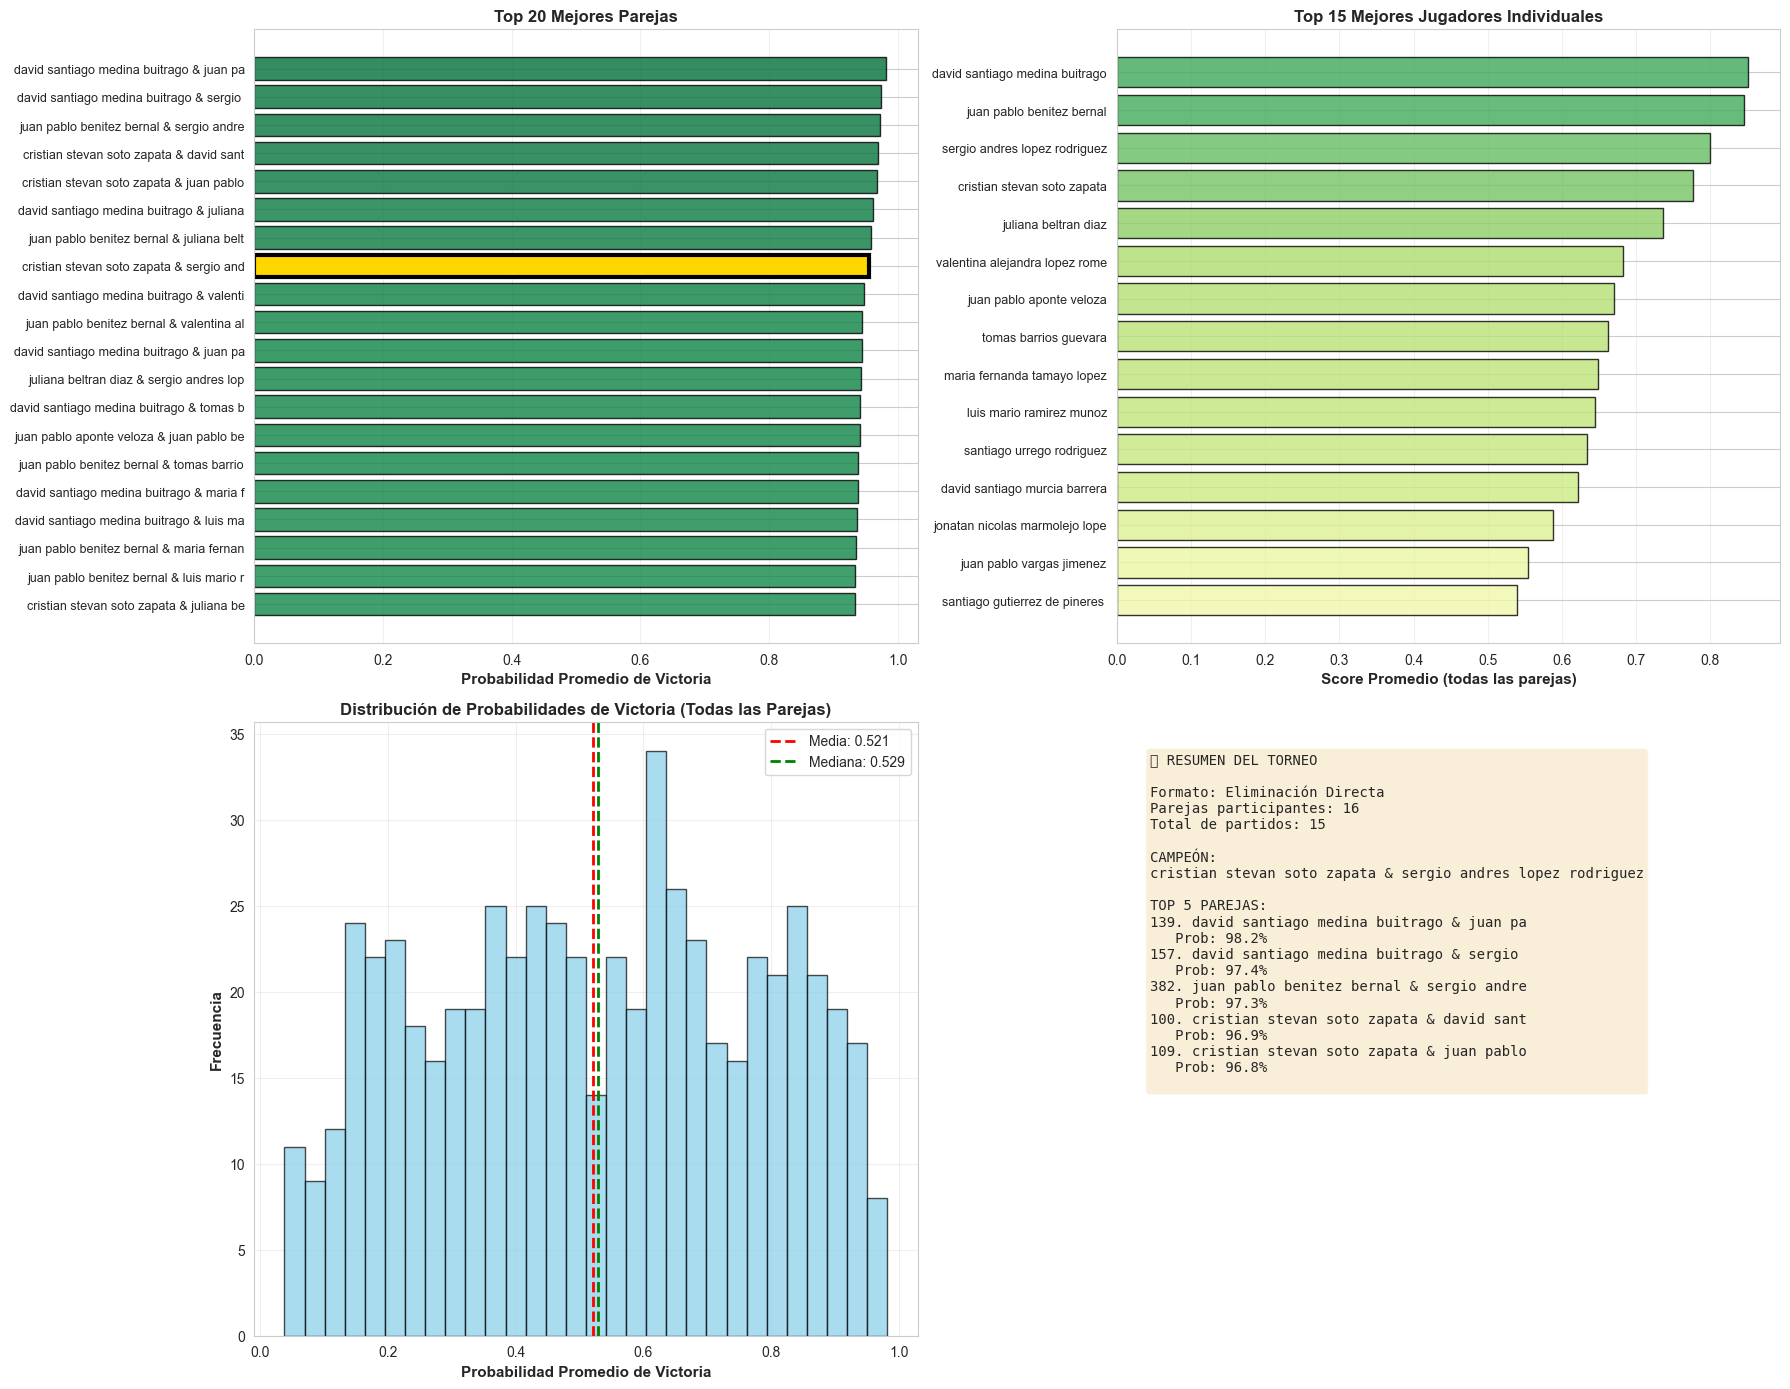


✅ Visualizaciones generadas


In [ ]:
# Visualización de resultados del torneo
print("="*80)
print("VISUALIZACIÓN DE RESULTADOS")
print("="*80)

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# 1. Top 20 Parejas por probabilidad de victoria
ax = axes[0, 0]
top_20_parejas = df_ranking_parejas.head(20)
y_pos = np.arange(len(top_20_parejas))
colors_parejas = plt.cm.RdYlGn(top_20_parejas['prob_victoria_promedio'])

ax.barh(y_pos, top_20_parejas['prob_victoria_promedio'], color=colors_parejas, alpha=0.8, edgecolor='black')
ax.set_yticks(y_pos)
ax.set_yticklabels([p[:40] for p in top_20_parejas['pareja']], fontsize=9)
ax.set_xlabel('Probabilidad Promedio de Victoria', fontsize=11, fontweight='bold')
ax.set_title('Top 20 Mejores Parejas', fontsize=12, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
ax.invert_yaxis()

# Destacar el campeón
campeon_idx = top_20_parejas[top_20_parejas['pareja'] == campeon].index
if len(campeon_idx) > 0:
    campeon_pos = list(top_20_parejas.index).index(campeon_idx[0])
    ax.barh(campeon_pos, top_20_parejas.iloc[campeon_pos]['prob_victoria_promedio'], 
            color='gold', alpha=1, edgecolor='black', linewidth=3)

# 2. Top 15 Jugadores Individuales
ax = axes[0, 1]
top_15_jugadores = df_ranking_jugadores.head(15)
y_pos_jug = np.arange(len(top_15_jugadores))
colors_jug = plt.cm.RdYlGn(top_15_jugadores['score_promedio'])

ax.barh(y_pos_jug, top_15_jugadores['score_promedio'], color=colors_jug, alpha=0.8, edgecolor='black')
ax.set_yticks(y_pos_jug)
ax.set_yticklabels([j[:30] for j in top_15_jugadores['jugador']], fontsize=9)
ax.set_xlabel('Score Promedio (todas las parejas)', fontsize=11, fontweight='bold')
ax.set_title('Top 15 Mejores Jugadores Individuales', fontsize=12, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
ax.invert_yaxis()

# 3. Distribución de probabilidades de victoria
ax = axes[1, 0]
ax.hist(df_ranking_parejas['prob_victoria_promedio'], bins=30, alpha=0.7, 
        color='skyblue', edgecolor='black')
ax.axvline(df_ranking_parejas['prob_victoria_promedio'].mean(), 
          color='red', linestyle='--', linewidth=2, label=f'Media: {df_ranking_parejas["prob_victoria_promedio"].mean():.3f}')
ax.axvline(df_ranking_parejas['prob_victoria_promedio'].median(), 
          color='green', linestyle='--', linewidth=2, label=f'Mediana: {df_ranking_parejas["prob_victoria_promedio"].median():.3f}')
ax.set_xlabel('Probabilidad Promedio de Victoria', fontsize=11, fontweight='bold')
ax.set_ylabel('Frecuencia', fontsize=11, fontweight='bold')
ax.set_title('Distribución de Probabilidades de Victoria (Todas las Parejas)', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)

# 4. Brackets del torneo - Tabla de resultados por ronda
ax = axes[1, 1]
ax.axis('off')

# Crear texto resumen del torneo
texto_torneo = f"🏆 RESUMEN DEL TORNEO\n\n"
texto_torneo += f"Formato: Eliminación Directa\n"
texto_torneo += f"Parejas participantes: {num_parejas_torneo}\n"
texto_torneo += f"Total de partidos: {len(df_resultados_torneo)}\n\n"
texto_torneo += f"CAMPEÓN:\n{campeon}\n\n"

# Mejores 5 parejas
texto_torneo += "TOP 5 PAREJAS:\n"
for idx, row in df_ranking_parejas.head(5).iterrows():
    texto_torneo += f"{idx+1}. {row['pareja'][:40]}\n"
    texto_torneo += f"   Prob: {row['prob_victoria_promedio']:.1%}\n"

ax.text(0.05, 0.95, texto_torneo, transform=ax.transAxes, 
        fontsize=10, verticalalignment='top', 
        fontfamily='monospace',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

print("\n✅ Visualizaciones generadas")

ANÁLISIS DE CONSISTENCIA - MÚLTIPLES SIMULACIONES

⏳ Ejecutando 100 simulaciones...

RONDA 1 - 16 parejas

  Partido 1:
    david santiago medina buitrago & juan pablo benitez bernal (54.9%)
      vs
    david santiago medina buitrago & sergio andres lopez rodriguez (45.1%)
    ✅ Ganador: david santiago medina buitrago & sergio andres lopez rodriguez

  Partido 2:
    juan pablo benitez bernal & sergio andres lopez rodriguez (54.9%)
      vs
    cristian stevan soto zapata & david santiago medina buitrago (45.1%)
    ✅ Ganador: cristian stevan soto zapata & david santiago medina buitrago

  Partido 3:
    cristian stevan soto zapata & juan pablo benitez bernal (54.9%)
      vs
    david santiago medina buitrago & juliana beltran diaz (45.1%)
    ✅ Ganador: david santiago medina buitrago & juliana beltran diaz

  Partido 4:
    juan pablo benitez bernal & juliana beltran diaz (54.9%)
      vs
    cristian stevan soto zapata & sergio andres lopez rodriguez (45.1%)
    ✅ Ganador: juan pab

,pareja,campeonatos,frecuencia
0,david santiago medina buitrago & juliana beltr...,13,0.13
1,david santiago medina buitrago & juan pablo be...,13,0.13
3,david santiago medina buitrago & valentina ale...,8,0.08
9,juan pablo benitez bernal & sergio andres lope...,8,0.08
5,david santiago medina buitrago & tomas barrios...,7,0.07
7,cristian stevan soto zapata & sergio andres lo...,7,0.07
6,david santiago medina buitrago & juan pablo ap...,6,0.06
10,juliana beltran diaz & sergio andres lopez rod...,6,0.06
12,cristian stevan soto zapata & david santiago m...,6,0.06
15,david santiago medina buitrago & sergio andres...,6,0.06



📊 ESTADÍSTICAS:
   Pareja más consistente: david santiago medina buitrago & juliana beltran diaz
   Campeonatos ganados: 13/100 (13.0%)
   Total de campeones diferentes: 16


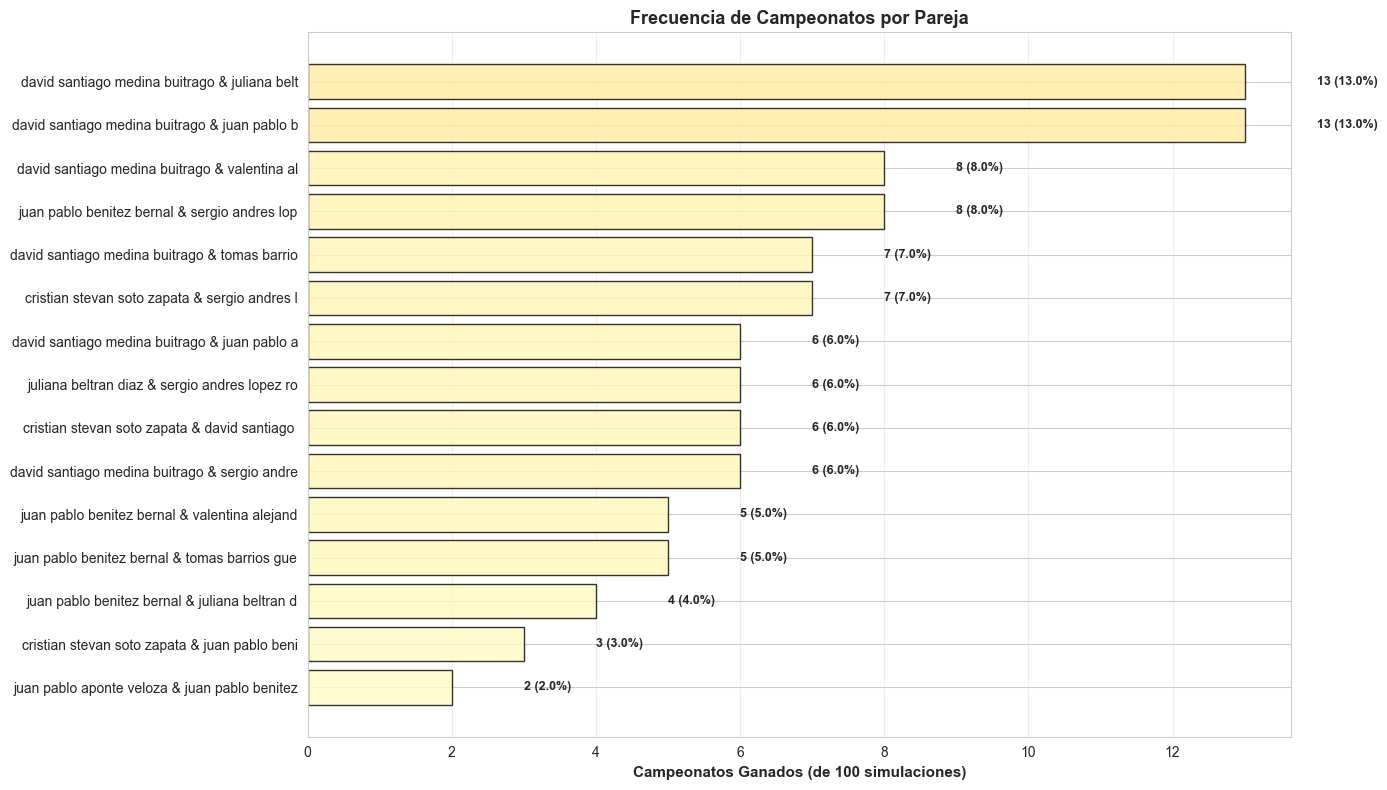

In [ ]:
# Análisis de consistencia - Múltiples simulaciones
print("="*80)
print("ANÁLISIS DE CONSISTENCIA - MÚLTIPLES SIMULACIONES")
print("="*80)

num_simulaciones = 100
campeones_frecuencia = {}

print(f"\n⏳ Ejecutando {num_simulaciones} simulaciones...")

for sim in range(num_simulaciones):
    campeon_sim, _ = simular_torneo(
        parejas_torneo, lr_model_eq, scaler_eq, features_equipos, semilla=sim
    )
    
    campeones_frecuencia[campeon_sim] = campeones_frecuencia.get(campeon_sim, 0) + 1
    
    if (sim + 1) % 20 == 0:
        print(f"   Completadas {sim + 1}/{num_simulaciones} simulaciones")

# Ordenar por frecuencia
df_campeones = pd.DataFrame([
    {'pareja': pareja, 'campeonatos': freq, 'frecuencia': freq/num_simulaciones}
    for pareja, freq in campeones_frecuencia.items()
]).sort_values('campeonatos', ascending=False)

print(f"\n✅ Simulaciones completadas")
print(f"\n🏆 PAREJAS QUE GANARON AL MENOS UN TORNEO ({len(df_campeones)} parejas):")
display(df_campeones)

print(f"\n📊 ESTADÍSTICAS:")
print(f"   Pareja más consistente: {df_campeones.iloc[0]['pareja']}")
print(f"   Campeonatos ganados: {df_campeones.iloc[0]['campeonatos']}/{num_simulaciones} ({df_campeones.iloc[0]['frecuencia']:.1%})")
print(f"   Total de campeones diferentes: {len(df_campeones)}")

# Visualización de frecuencia de campeones
fig, ax = plt.subplots(1, 1, figsize=(14, 8))

top_campeones = df_campeones.head(15)
y_pos = np.arange(len(top_campeones))
colors_camp = plt.cm.YlOrRd(top_campeones['frecuencia'])

bars = ax.barh(y_pos, top_campeones['campeonatos'], color=colors_camp, alpha=0.8, edgecolor='black')
ax.set_yticks(y_pos)
ax.set_yticklabels([p[:45] for p in top_campeones['pareja']], fontsize=10)
ax.set_xlabel(f'Campeonatos Ganados (de {num_simulaciones} simulaciones)', fontsize=11, fontweight='bold')
ax.set_title('Frecuencia de Campeonatos por Pareja', fontsize=13, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
ax.invert_yaxis()

# Añadir valores en las barras
for i, (bar, val, freq) in enumerate(zip(bars, top_campeones['campeonatos'], top_campeones['frecuencia'])):
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height()/2, 
            f'{val} ({freq:.1%})', 
            ha='left', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()